# Resolution refinement and the rodeo algorithm on the Hubbard model — lattice refinement, symmetry protection and gate budgets

This notebook is the computational companion of paper III of the EIGEN-Q series.  Papers I and II
implemented the pipeline *coarse eigenstate → prolongation → adiabatic resolution refinement →
rodeo filter* on the pairing Hamiltonian, where "resolution" was the number of single-particle
levels.  Here we carry the same pipeline, the same exact-diagonalisation (ED) benchmarks and the
same cost accounting to the Hubbard model

$$H=-t\sum_{\langle ij\rangle\sigma}\big(c^\dagger_{i\sigma}c_{j\sigma}+\mathrm{h.c.}\big)+U\sum_i n_{i\uparrow}n_{i\downarrow},$$

and to the form of refinement for which the method was proposed: a **lattice** refinement in which
every coarse site is resolved into a block of fine sites and the prolongation maps the coarse
orbital onto the bonding combination of its block.

All physics lives in `pairinglib.hubbard` (tested, `tests/test_hubbard.py`); the ED conventions
are those of `paper3/Hubbard.ipynb` (block Jordan–Wigner ordering, sorted occupation masks,
$H=K_\uparrow\otimes1+1\otimes K_\downarrow+U\,\mathrm{diag}$).  We work at $t=1$ with open
boundary conditions.  The sections follow the paper: model and ED reference (1), prolongation and
the Galerkin coarse model (2), the open chain $4\to8$ along two refinement paths (3), which gap
controls the refinement (4), the dimer bootstrap and composed chains (5), $8\to16$ sites (6), two
dimensions and the wrong symmetry sector (7), the rodeo filter (8), the UCCSD comparator (9),
circuit-level costs (10) and a summary (11).

---
## 1&nbsp; The model and its exact-diagonalisation reference

The Hamiltonian conserves $N_\uparrow$ and $N_\downarrow$; we work in one sector of dimension
$\binom{N}{N_\uparrow}\binom{N}{N_\downarrow}$.  With the up orbitals Jordan–Wigner ordered before
the down orbitals, a down hop crosses all up electrons twice and the sector Hamiltonian is the
Kronecker sum of two one-species hopping matrices plus the diagonal interaction.  We validate the
builder against free fermions ($U=0$), the analytic dimer $E_0=\tfrac12(U-\sqrt{U^2+16t^2})$, and
the term decomposition used later for product formulas.

In [1]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

# --- validation of the sector ED against closed forms ---
N, bonds = hb.chain(2)
for U in (0.0, 4.0, 8.0):
    E0 = np.linalg.eigvalsh(hb.H_hubbard(N, bonds, 1, 1, U)[0].toarray())[0]
    Ean = 0.5*(U - np.sqrt(U**2 + 16))
    assert abs(E0 - Ean) < 1e-12
    print(f"dimer U={U:3.0f}: E0 = {E0:+.10f} == (U - sqrt(U^2+16t^2))/2")
for kind, L, (nu, nd) in (("chain", 8, (2, 2)), ("square", 3, (2, 1))):
    N, bonds = hb.chain(L) if kind == "chain" else hb.square(L)
    T1 = np.zeros((N, N))
    for i, j in bonds: T1[i, j] = T1[j, i] = -1.0
    e1 = np.linalg.eigvalsh(T1)
    H, _ = hb.H_hubbard(N, bonds, nu, nd, 0.0)
    E0 = hb.ground(H, 1)[0][0]
    assert abs(E0 - (e1[:nu].sum() + e1[:nd].sum())) < 1e-9
    print(f"{kind:6s} L={L} U=0 ({nu},{nd}): E0 = {E0:+.10f} == band filling")
N, bonds = hb.chain(6)
H, _ = hb.H_hubbard(N, bonds, 3, 3, 4.0)
terms = hb.hubbard_terms(N, bonds, 3, 3, 4.0)
assert abs(sum(T.toarray() for T in terms) - H.toarray()).max() < 1e-12
print(f"term decomposition [K_even, K_odd, U diag] sums to H (L=6, half filling, dim {H.shape[0]})")
print("\nsector dimensions used below:")
for lab, N, nu, nd in (("chain L=2", 2, 2, 2), ("chain L=4", 4, 2, 2), ("chain L=8", 8, 2, 2), ("chain L=16", 16, 2, 2),
                       ("2x2", 4, 1, 1), ("4x4", 16, 1, 1), ("2x2", 4, 2, 2), ("4x4", 16, 2, 2)):
    print(f"  {lab:11s} ({nu},{nd}): {comb(N, nu)*comb(N, nd):6d}")


dimer U=  0: E0 = -2.0000000000 == (U - sqrt(U^2+16t^2))/2
dimer U=  4: E0 = -0.8284271247 == (U - sqrt(U^2+16t^2))/2
dimer U=  8: E0 = -0.4721359550 == (U - sqrt(U^2+16t^2))/2
chain  L=8 U=0 (2,2): E0 = -6.8229482556 == band filling
square L=3 U=0 (2,1): E0 = -7.0710678119 == band filling
term decomposition [K_even, K_odd, U diag] sums to H (L=6, half filling, dim 400)

sector dimensions used below:
  chain L=2   (2,2):      1
  chain L=4   (2,2):     36
  chain L=8   (2,2):    784
  chain L=16  (2,2):  14400
  2x2         (1,1):     16
  4x4         (1,1):    256
  2x2         (2,2):     36
  4x4         (2,2):  14400


---
## 2&nbsp; Prolongation and the Galerkin coarse Hamiltonian

A refinement step maps $N_c$ coarse sites onto $N_f=bN_c$ fine sites ($b=2$ for the chain, $b=4$
for the square lattice).  The prolongation sends the coarse orbital to the normalized bonding
combination of its block,
$c^\dagger_{c\sigma}\mapsto s^\dagger_{c\sigma}=b^{-1/2}\sum_{f\in B(c)}c^\dagger_{f\sigma}$,
and a coarse determinant to the product of $s^\dagger$ operators; $P$ is an isometry from the coarse
sector into the fine sector.  On a device it is one Givens rotation per block per spin ($b=2$).

The coarse Hamiltonian whose eigenstate is refined is the Galerkin projection
$H_{\rm low}=P^\dagger H_{\rm high}P$, which makes $\langle P\psi_{\rm low}|H_{\rm high}|P\psi_{\rm low}\rangle=E_{\rm low}$
exact.  Projecting the hopping and interaction terms with the bonding map gives a closed form:
an intra-block bond contributes $-t$ per particle, an inter-block bond $\tfrac12 s^\dagger_cs_{c'}$,
and $U\,n_{f\uparrow}n_{f\downarrow}\to(U/b)\,n_{s\uparrow}n_{s\downarrow}$ summed over the block, so

$$\text{chain: } H_{\rm low}=H_{\rm Hubbard}(L;\,t/2,\,U/2)-tN,\qquad
\text{square: } H_{\rm low}=H_{\rm Hubbard}(L\times L;\,t/2,\,U/4)-2tN .$$

In one dimension $U/t$ is preserved: the hierarchy $L\to2L\to4L\to\cdots$ is self-similar.  We
verify both identities to machine precision and tabulate the prolonged overlap $p_0$.

In [2]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

for kind, L, nu, nd in (("chain", 4, 2, 2), ("chain", 2, 2, 2), ("square", 2, 1, 1)):
    if kind == "chain": (Nc, bc), (Nf, bf), blocks, intra = hb.refine_chain(L)
    else:               (Nc, bc), (Nf, bf), blocks, intra = hb.refine_square(L)
    for U in (0.0, 4.0):
        Hf, _ = hb.H_hubbard(Nf, bf, nu, nd, U)
        P = hb.prolong(Nc, Nf, blocks, nu, nd)
        Hl = P.T @ Hf.toarray() @ P
        tl, Ul, c = hb.galerkin_params(kind, 1.0, U, nu + nd)
        Hc = hb.H_hubbard(Nc, bc, nu, nd, Ul, t=tl)[0].toarray() + c*np.eye(len(Hl))
        err = abs(Hl - Hc).max(); iso = abs(P.T @ P - np.eye(P.shape[1])).max()
        print(f"{kind:6s} {Nc:2d}->{Nf:2d} ({nu},{nd}) U={U:.0f}: |P^T H P - H_Hubbard(t'={tl}, U'={Ul}) - ({c})| = {err:.1e}, |P^T P - 1| = {iso:.1e}")
print("\nprolonged overlap p0 = |<Psi_high|P psi_low>|^2 of the coarse ground state:")
for kind, L, nu, nd in (("chain", 2, 2, 2), ("chain", 4, 2, 2), ("chain", 8, 2, 2), ("square", 2, 1, 1)):
    if kind == "chain": (Nc, bc), (Nf, bf), blocks, intra = hb.refine_chain(L)
    else:               (Nc, bc), (Nf, bf), blocks, intra = hb.refine_square(L)
    row = []
    for U in (0.0, 2.0, 4.0, 8.0):
        Hf, _ = hb.H_hubbard(Nf, bf, nu, nd, U)
        w, V = hb.ground(Hf, 2)
        P = hb.prolong(Nc, Nf, blocks, nu, nd, sparse=True)
        ps = hb.prolonged_state(Hf, P)
        row.append(abs(np.vdot(V[:, 0], ps["Phi0"]))**2)
    print(f"  {kind:6s} {Nc:2d}->{Nf:2d} ({nu},{nd}):  " + "  ".join(f"U={U:.0f}: {p:.4f}" for U, p in zip((0, 2, 4, 8), row)))


chain   4-> 8 (2,2) U=0: |P^T H P - H_Hubbard(t'=0.5, U'=0.0) - (-4.0)| = 3.6e-15, |P^T P - 1| = 8.9e-16
chain   4-> 8 (2,2) U=4: |P^T H P - H_Hubbard(t'=0.5, U'=2.0) - (-4.0)| = 3.6e-15, |P^T P - 1| = 8.9e-16
chain   2-> 4 (2,2) U=0: |P^T H P - H_Hubbard(t'=0.5, U'=0.0) - (-4.0)| = 3.6e-15, |P^T P - 1| = 8.9e-16
chain   2-> 4 (2,2) U=4: |P^T H P - H_Hubbard(t'=0.5, U'=2.0) - (-4.0)| = 8.3e-17, |P^T P - 1| = 8.9e-16
square  4->16 (1,1) U=0: |P^T H P - H_Hubbard(t'=0.5, U'=0.0) - (-4.0)| = 0.0e+00, |P^T P - 1| = 0.0e+00
square  4->16 (1,1) U=4: |P^T H P - H_Hubbard(t'=0.5, U'=1.0) - (-4.0)| = 0.0e+00, |P^T P - 1| = 0.0e+00

prolonged overlap p0 = |<Psi_high|P psi_low>|^2 of the coarse ground state:
  chain   2-> 4 (2,2):  U=0: 0.8050  U=2: 0.7541  U=4: 0.6449  U=8: 0.4804


  chain   4-> 8 (2,2):  U=0: 0.7773  U=2: 0.8139  U=4: 0.7974  U=8: 0.7501


  chain   8->16 (2,2):  U=0: 0.9119  U=2: 0.8929  U=4: 0.8692  U=8: 0.8400
  square  4->16 (1,1):  U=0: 0.8050  U=2: 0.8289  U=4: 0.8396  U=8: 0.8451


---
## 3&nbsp; The open chain refined from four to eight sites along two paths

**Path A** is the shift-controlled projector path of papers I and II,
$H_A(s)=\cos^2(\tfrac{\pi s}2)P(H_{\rm low}-\mu)P^\dagger+\sin^2(\tfrac{\pi s}2)(H_{\rm high}-\mu)$,
with $\mu=E_{\rm low}+\mu_{\rm buf}$.  **Path B** keeps the Hamiltonian two-local in the laboratory
frame: it adds an extra hopping $\Lambda$ on the intra-block bonds and switches it off,
$H_B(s)=H_{\rm high}-\Lambda\cos^2(\tfrac{\pi s}2)\sum_{\rm intra}\sum_\sigma(c^\dagger_{f\sigma}c_{f'\sigma}+{\rm h.c.})$
— the dimerized chain being adiabatically made uniform.  At finite $\Lambda$ the ground state of
$H_B(0)$ differs from the prolonged state by an admixture of order $t/\Lambda$, so Path B carries a
residual $1-p\simeq c\,(t/\Lambda)^2$ to the end.

We propagate exactly with 96 slices (the slice propagators are reused for every $T$) and report
$p(T)=|\langle\Psi_{\rm high}|\psi(T)\rangle|^2$ for $N_\uparrow=N_\downarrow=2$, $U/t=0,2,4,8$.

chain 4->8, (2,2), dims 36 -> 784  [268 s]

 U/t      E_low     E_high     p0  Delta  D_eff |    A, mu_buf=1    A, mu_buf=2    B, Lambda=8   B, Lambda=16
                                                | p(8)  p(16) p(32) p(8)  p(16) p(32) p(8)  p(16) p(32) p(8)  p(16) p(32)
   0  -6.236068  -6.822948  0.777  0.532  0.879 | 0.98429 0.99892 0.99996 | 0.99718 0.99997 1.00000 | 0.98757 0.99546 0.99504 | 0.98040 0.99660 0.99838
   2  -5.437971  -6.032090  0.814  0.319  0.780 | 0.98737 0.99848 0.99993 | 0.99876 0.99996 1.00000 | 0.99177 0.99384 0.99497 | 0.98765 0.99594 0.99849
   4  -4.976573  -5.634427  0.797  0.223  0.588 | 0.98860 0.99814 0.99989 | 0.99837 0.99994 1.00000 | 0.98286 0.99239 0.99385 | 0.97923 0.99316 0.99769
   8  -4.558586  -5.277973  0.750  0.137  0.366 | 0.99013 0.99818 0.99985 | 0.99761 0.99991 1.00000 | 0.97528 0.98912 0.99440 | 0.97172 0.99205 0.99731

Path B: overlap of the prolonged state with the exact ground state of H_B(0), and the finite-Lambda ceiling 1-p(T=6

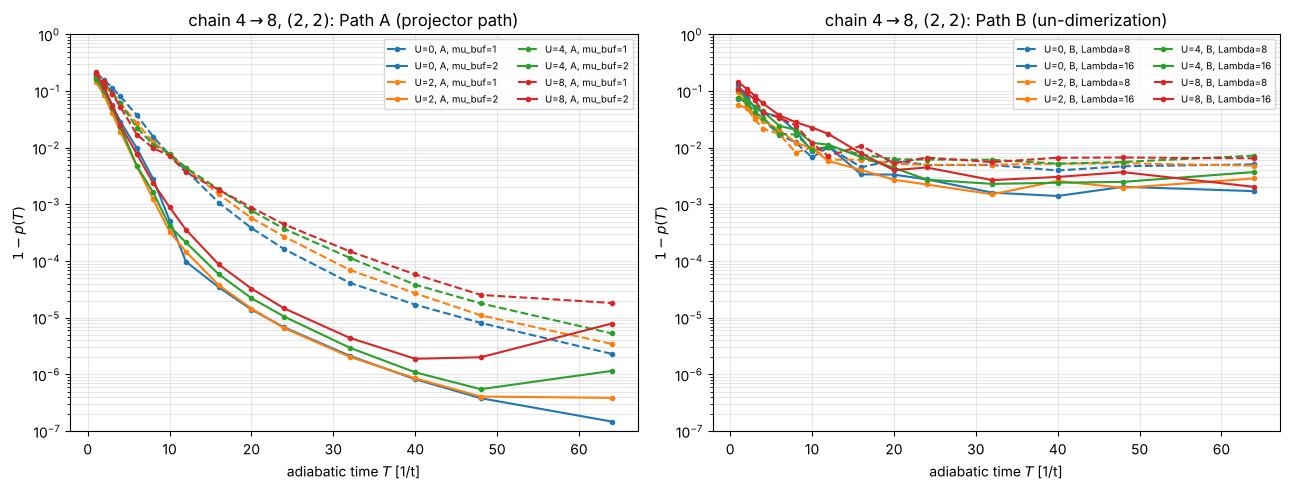

In [3]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

Ts = np.array([0, 1, 2, 3, 4, 6, 8, 10, 12, 16, 20, 24, 32, 40, 48, 64])
Us = (0.0, 2.0, 4.0, 8.0)
MU_BUFS, LAMS, MSL = (1.0, 2.0), (8.0, 16.0), 96
(Nc, bc), (Nf, bf), blocks, intra = hb.refine_chain(4)
chain48 = {}
t0 = time.time()
for U in Us:
    Hf, (Sup, Sdn) = hb.H_hubbard(Nf, bf, 2, 2, U); Hd = Hf.toarray()
    wf, Vf = np.linalg.eigh(Hd); Psih = Vf[:, 0]
    P = hb.prolong(Nc, Nf, blocks, 2, 2); ps = hb.prolonged_state(Hf, P)
    Deff, c2 = hb.effective_gap(ps["Phi0"], wf, Vf)
    r = dict(E_low=ps["El"], E_high=wf[0], p0=c2[0], gap=wf[1]-wf[0], Deff=Deff, wf=wf, Vf=Vf, Phi0=ps["Phi0"],
             Hf=Hd, Hl=ps["Hl"], P=P, c2=c2, paths={})
    for mb in MU_BUFS:
        Hle, Hhs = hb.path_A(Hd, ps["Hl"], P, ps["El"] + mb)
        ov, eigs = hb.refine_overlaps(ps["Phi0"], Hle, Hhs, Ts, Psih, MSL)
        s, W = hb.path_gap(Hle, Hhs, 21)
        r["paths"][f"A, mu_buf={mb:.0f}"] = dict(ov=ov, gap=W[:, 1]-W[:, 0], s=s, Hle=Hle, Hhs=Hhs,
                                               states={T: hb.evolve(ps["Phi0"], eigs, T) for T in (8, 16, 32)})
        del eigs                                    # 96 dense eigendecompositions: keep only the states
    Kin = hb.hubbard_terms(Nf, intra, 2, 2, 0.0, layers=[list(range(len(intra)))])[0].toarray()
    for Lam in LAMS:
        Hle, Hhs = hb.path_B(Hd, Kin, Lam)
        ov, eigs = hb.refine_overlaps(ps["Phi0"], Hle, Hhs, Ts, Psih, MSL)
        s, W = hb.path_gap(Hle, Hhs, 21)
        w0, V0 = np.linalg.eigh(Hle)
        r["paths"][f"B, Lambda={Lam:.0f}"] = dict(ov=ov, gap=W[:, 1]-W[:, 0], s=s, Hle=Hle, Hhs=Hhs,
                                                 start=abs(np.vdot(V0[:, 0], ps["Phi0"]))**2,
                                                 states={T: hb.evolve(ps["Phi0"], eigs, T) for T in (8, 16, 32)})
        del eigs
    chain48[U] = r
print(f"chain 4->8, (2,2), dims {chain48[0.0]['Hl'].shape[0]} -> {chain48[0.0]['Hf'].shape[0]}  [{time.time()-t0:.0f} s]\n")
print(f"{'U/t':>4s} {'E_low':>10s} {'E_high':>10s} {'p0':>6s} {'Delta':>6s} {'D_eff':>6s} | " + " ".join(f"{k:>14s}" for k in chain48[0.0]["paths"]))
print(f"{'':>4s} {'':>10s} {'':>10s} {'':>6s} {'':>6s} {'':>6s} | " + " ".join(f"{'p(8)  p(16) p(32)':>14s}" for k in chain48[0.0]["paths"]))
for U, r in chain48.items():
    cells_ = []
    for k, v in r["paths"].items():
        cells_.append(" ".join(f"{v['ov'][list(Ts).index(T)]:.5f}" for T in (8, 16, 32)))
    print(f"{U:4.0f} {r['E_low']:10.6f} {r['E_high']:10.6f} {r['p0']:6.3f} {r['gap']:6.3f} {r['Deff']:6.3f} | " + " | ".join(cells_))
print("\nPath B: overlap of the prolonged state with the exact ground state of H_B(0), and the finite-Lambda ceiling 1-p(T=64):")
for U, r in chain48.items():
    print(f"  U={U:.0f}: " + "   ".join(f"{k}: start {v['start']:.5f}, 1-p(64) = {1-v['ov'][-1]:.1e}" for k, v in r["paths"].items() if k.startswith("B")))
print("\nminimum of the sector gap along the path (and where it sits):")
for U, r in chain48.items():
    print(f"  U={U:.0f}: " + "  ".join(f"{k}: {v['gap'].min():.3f} @ s={v['s'][v['gap'].argmin()]:.2f}" for k, v in r["paths"].items()))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
cols = {0.0: "C0", 2.0: "C1", 4.0: "C2", 8.0: "C3"}
for U, r in chain48.items():
    for k, v in r["paths"].items():
        a = ax[0] if k.startswith("A") else ax[1]
        ls = "-" if ("mu_buf=2" in k or "Lambda=16" in k) else "--"
        a.semilogy(Ts[1:], np.maximum(1 - v["ov"][1:], 1e-12), ls, color=cols[U], marker="o", ms=3,
                   label=f"U={U:.0f}, {k}")
for a, ttl in zip(ax, ("Path A (projector path)", "Path B (un-dimerization)")):
    a.set_xlabel("adiabatic time $T$ [1/t]"); a.set_ylabel("$1-p(T)$"); a.set_title(f"chain $4\\to8$, $(2,2)$: {ttl}")
    a.grid(alpha=0.3, which="both"); a.legend(fontsize=7, ncol=2); a.set_ylim(1e-7, 1)
plt.tight_layout(); plt.show()


The prolonged state is a good start at every coupling ($p_0=0.75$–$0.81$), the free-fermion
case is not trivial because the bonding modes are not the lowest fine orbitals, and Path A with
$\mu_{\rm buf}=2t$ reaches $p>0.9999$ at $T=16/t$ for all four couplings although the sector gap
of the fine Hamiltonian falls by a factor four.  Path B refines at a comparable rate but
saturates at the finite-$\Lambda$ ceiling, which scales as $(t/\Lambda)^2$ (the ratio of the
$\Lambda=8t$ and $16t$ ceilings is close to four).

---
## 4&nbsp; Which gap controls the refinement: symmetry protection

Both terms of $H_A(s)$ commute with the total spin $\mathbf S^2$ and with the reflection of the
chain, and the prolongation maps irreducible representations onto themselves.  The transported
state therefore never leaves the symmetry sector of the coarse ground state (a reflection-even
singlet here), and only states of that sector can be excited.  We make this explicit by
decomposing the prolonged state over the fine eigenstates, labelling every eigenstate by
$S$ (from $\langle\mathbf S^2\rangle=S_z(S_z+1)+\|S^+\psi\|^2$) and by its reflection parity,
and by following the gap *within the sector* along the path.  $\Delta_{\rm eff}$, the lowest
excitation that carries weight, is the quantity that sets the refinement time and the rodeo width;
we also evaluate the Jansen–Ruskai–Seiler sufficient time of paper I (Sec. IV.E) with the sector
gap and with the symmetry-resolved gap.

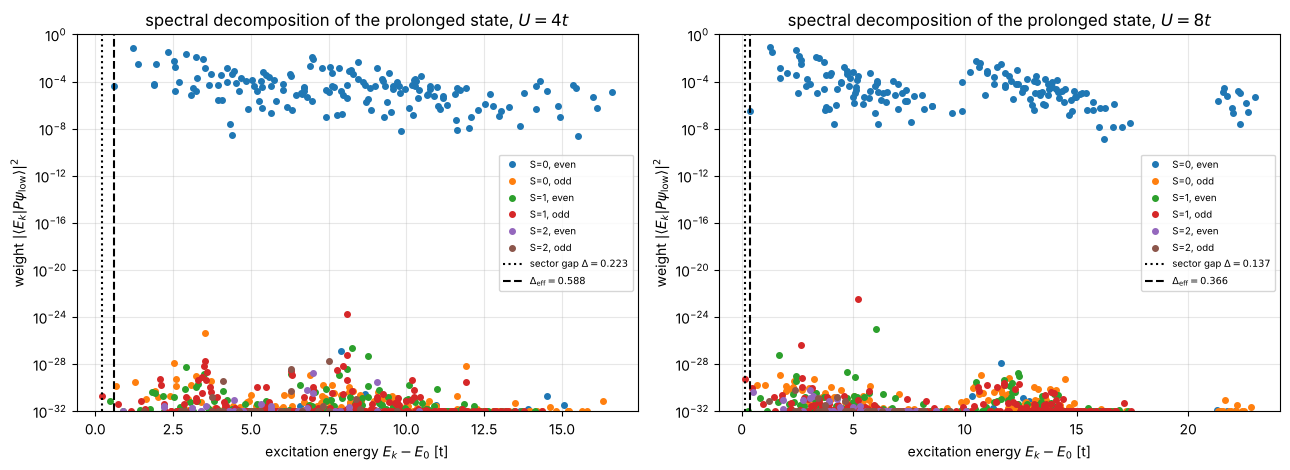

lowest fine excitations, their symmetry sector and their weight in the prolonged state:


  U=0: ground state S=0, parity +1; sector gap 0.532, D_eff 0.879
       E_1-E_0 = 0.532  S=1 parity -1  weight 1.8e-32
       E_2-E_0 = 0.532  S=0 parity -1  weight 2.3e-30
       E_3-E_0 = 0.879  S=0 parity +1  weight 1.1e-02
       E_4-E_0 = 0.879  S=1 parity +1  weight 1.2e-27
       E_5-E_0 = 1.064  S=0 parity +1  weight 3.9e-32
       E_6-E_0 = 1.185  S=1 parity +1  weight 1.1e-31
       weight in the (S=0, parity +1) sector: 0.925232484554


  U=2: ground state S=0, parity +1; sector gap 0.319, D_eff 0.780
       E_1-E_0 = 0.319  S=1 parity -1  weight 6.8e-32
       E_2-E_0 = 0.615  S=0 parity -1  weight 9.6e-31
       E_3-E_0 = 0.623  S=1 parity +1  weight 5.9e-34
       E_4-E_0 = 0.780  S=0 parity +1  weight 8.2e-04
       E_5-E_0 = 0.981  S=1 parity +1  weight 1.4e-31
       E_6-E_0 = 1.031  S=1 parity -1  weight 6.2e-31
       weight in the (S=0, parity +1) sector: 1.000000000000


  U=4: ground state S=0, parity +1; sector gap 0.223, D_eff 0.588
       E_1-E_0 = 0.223  S=1 parity -1  weight 1.9e-31
       E_2-E_0 = 0.459  S=1 parity +1  weight 6.7e-32
       E_3-E_0 = 0.588  S=0 parity +1  weight 4.6e-05
       E_4-E_0 = 0.654  S=0 parity -1  weight 1.2e-30
       E_5-E_0 = 0.739  S=1 parity -1  weight 4.1e-32
       E_6-E_0 = 0.876  S=2 parity +1  weight 5.2e-34
       weight in the (S=0, parity +1) sector: 1.000000000000


  U=8: ground state S=0, parity +1; sector gap 0.137, D_eff 0.366
       E_1-E_0 = 0.137  S=1 parity -1  weight 5.6e-30
       E_2-E_0 = 0.286  S=1 parity +1  weight 2.0e-33
       E_3-E_0 = 0.366  S=0 parity +1  weight 3.0e-07
       E_4-E_0 = 0.448  S=1 parity -1  weight 9.8e-31
       E_5-E_0 = 0.519  S=2 parity +1  weight 4.4e-31
       E_6-E_0 = 0.680  S=0 parity -1  weight 1.7e-30
       weight in the (S=0, parity +1) sector: 1.000000000000


In [4]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

Rop = hb.site_permutation(hb.reflection_chain(Nf), Nf, 2, 2)
def labels(V, N=Nf):
    S = np.array([hb.total_spin(V[:, k], N, 2, 2)[1] for k in range(V.shape[1])])
    par = np.array([float(np.vdot(V[:, k], Rop @ V[:, k]).real) for k in range(V.shape[1])])
    return np.round(S).astype(int), np.sign(par).astype(int)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for a, U in zip(ax, (4.0, 8.0)):
    r = chain48[U]; wf, Vf, c2 = r["wf"], r["Vf"], r["c2"]
    S, par = labels(Vf)
    dE = wf - wf[0]
    for (s_, p_), col, lab in (((0, 1), "C0", "S=0, even"), ((0, -1), "C1", "S=0, odd"), ((1, 1), "C2", "S=1, even"), ((1, -1), "C3", "S=1, odd"), ((2, 1), "C4", "S=2, even"), ((2, -1), "C5", "S=2, odd")):
        m = (S == s_) & (par == p_) & (dE > 1e-9)
        if m.any():
            a.semilogy(dE[m], np.maximum(c2[m], 1e-32), "o", ms=4, color=col, label=lab)
    a.axvline(r["gap"], color="k", ls=":", label=f"sector gap $\\Delta={r['gap']:.3f}$")
    a.axvline(r["Deff"], color="k", ls="--", label=f"$\\Delta_{{\\rm eff}}={r['Deff']:.3f}$")
    a.set_ylim(1e-32, 1); a.set_xlabel("excitation energy $E_k-E_0$ [t]"); a.set_ylabel("weight $|\\langle E_k|P\\psi_{\\rm low}\\rangle|^2$")
    a.set_title(f"spectral decomposition of the prolonged state, $U={U:.0f}t$"); a.legend(fontsize=7); a.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

print("lowest fine excitations, their symmetry sector and their weight in the prolonged state:")
for U, r in chain48.items():
    S, par = labels(r["Vf"]); dE = r["wf"] - r["wf"][0]
    S0, p0_ = S[0], par[0]
    print(f"  U={U:.0f}: ground state S={S0}, parity {p0_:+d}; sector gap {r['gap']:.3f}, D_eff {r['Deff']:.3f}")
    for k in range(1, 7):
        print(f"       E_{k}-E_0 = {dE[k]:.3f}  S={S[k]} parity {par[k]:+d}  weight {r['c2'][k]:.1e}")
    tot_same = r["c2"][(S == S0) & (par == p0_)].sum()
    print(f"       weight in the (S={S0}, parity {p0_:+d}) sector: {tot_same:.12f}")


Path A, mu_buf = 2: JRS sufficient time T_b(eps=1e-2) with the sector gap and with the symmetry-resolved gap
 U/t  min gap min gap_eff  |B-A|  T_b(gap) T_b(gap_eff)   T*


   0    0.532       0.879  11.06     57149        11583   10


   2    0.319       0.780  11.84    253953        19904   10


   4    0.223       0.588  13.91   1010649        63772   10


   8    0.137       0.366  20.01  10087851       580380   10


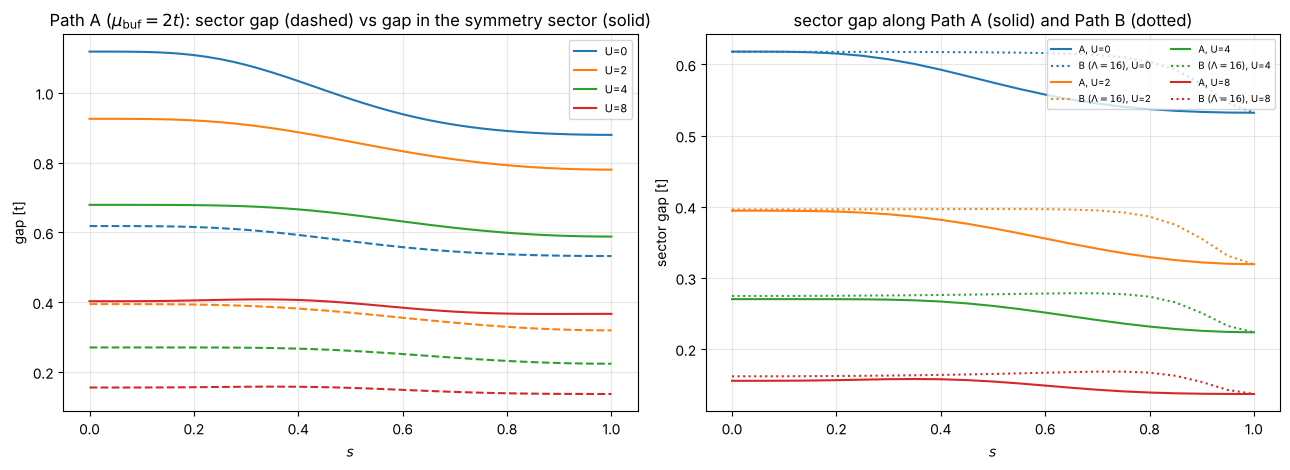

In [5]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

# --- the gap along Path A: sector gap vs the gap within the symmetry sector of the tracked state ---
def sector_gap_along_path(Hle, Hhs, ns=41, N=Nf):
    s_grid = np.linspace(0, 1, ns); gsec, geff = [], []
    for s in s_grid:
        H = np.cos(np.pi*s/2)**2*Hle + np.sin(np.pi*s/2)**2*Hhs
        w, V = np.linalg.eigh(H)
        S, par = labels(V[:, :40])
        same = np.where((S == S[0]) & (par == par[0]))[0]
        gsec.append(w[1] - w[0]); geff.append(w[same[1]] - w[0])
    return s_grid, np.array(gsec), np.array(geff)

trapz = getattr(np, "trapezoid", None) or np.trapz
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
print("Path A, mu_buf = 2: JRS sufficient time T_b(eps=1e-2) with the sector gap and with the symmetry-resolved gap")
print(f"{'U/t':>4s} {'min gap':>8s} {'min gap_eff':>11s} {'|B-A|':>6s} {'T_b(gap)':>9s} {'T_b(gap_eff)':>12s} {'T*':>4s}")
bound48 = {}
for U, r in chain48.items():
    v = r["paths"]["A, mu_buf=2"]
    s, gs, ge = sector_gap_along_path(v["Hle"], v["Hhs"], 41)
    ax[0].plot(s, gs, "--", color=cols[U]); ax[0].plot(s, ge, "-", color=cols[U], label=f"U={U:.0f}")
    nBA = np.linalg.norm(v["Hhs"] - v["Hle"], 2)
    dH1 = (np.pi/2)*np.abs(np.sin(np.pi*s))*nBA; dH2 = (np.pi**2/2)*np.abs(np.cos(np.pi*s))*nBA
    Tb = {k: trapz(dH2/g**2 + 7*dH1**2/g**3, s)/np.sqrt(1e-2) for k, g in (("sec", gs), ("eff", ge))}
    hit = np.where(1 - v["ov"] < 1e-3)[0]; Tstar = Ts[hit[0]] if hit.size else np.nan
    bound48[U] = dict(gap=gs.min(), geff=ge.min(), nBA=nBA, Tb_sec=Tb["sec"], Tb_eff=Tb["eff"], Tstar=Tstar)
    print(f"{U:4.0f} {gs.min():8.3f} {ge.min():11.3f} {nBA:6.2f} {Tb['sec']:9.0f} {Tb['eff']:12.0f} {Tstar:4.0f}")
ax[0].set_xlabel("$s$"); ax[0].set_ylabel("gap [t]"); ax[0].set_title("Path A ($\\mu_{\\rm buf}=2t$): sector gap (dashed) vs gap in the symmetry sector (solid)")
ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
for U, r in chain48.items():
    ax[1].plot(r["paths"]["A, mu_buf=2"]["s"], r["paths"]["A, mu_buf=2"]["gap"], "-", color=cols[U], label=f"A, U={U:.0f}")
    ax[1].plot(r["paths"]["B, Lambda=16"]["s"], r["paths"]["B, Lambda=16"]["gap"], ":", color=cols[U], label=f"B ($\\Lambda=16$), U={U:.0f}")
ax[1].set_xlabel("$s$"); ax[1].set_ylabel("sector gap [t]"); ax[1].set_title("sector gap along Path A (solid) and Path B (dotted)"); ax[1].legend(fontsize=7, ncol=2); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()


The lowest fine excitations are triplets or reflection-odd states with weights at the level of
$10^{-28}$ (round-off), and the first state that carries weight lies at $\Delta_{\rm eff}$, two to
three times the sector gap.  Along the path the gap within the symmetry sector never closes
towards the small sector gap, which is why $T^*$ is flat in $U$; the sufficient time of the JRS
bound remains two to three orders of magnitude above $T^*$ even with the symmetry-resolved gap, as
in paper I.

---
## 5&nbsp; Bootstrapping from the filled dimer and composing refinement steps

The self-similar hierarchy can start from the two-site dimer with $N_\uparrow=N_\downarrow=2$, whose
sector contains a single state (both sites doubly occupied, $E_{\rm low}=U-4t$): a computational
basis state, with no variational preprocessing, in the spirit of the $k=2$ determinant of paper I.
We refine it $2\to4$, then compose the steps $2\to4\to8$ with the *refined* (not the exact) state
as the input of the next step, the shift $\mu$ being referenced to the variational coarse energy
$\langle\psi|H_{\rm low}|\psi\rangle$, and compare with a single-shot refinement $2\to8$ in which
each coarse site is resolved into a block of four.

filled dimer 2 -> 4, (2,2), Path A with mu_buf = 2:
 U/t   E_low   E_high     p0  Delta  D_eff  min gap | p(2) p(4) p(8) p(12) p(16) p(24) p(32)
   0  -4.000  -4.4721  0.805  1.236  2.236    1.236 | 0.9068 0.9923 0.9999 1.0000 1.0000 1.0000 1.0000
   2  -2.000  -2.8759  0.754  0.789  1.851    0.789 | 0.8916 0.9809 0.9995 0.9999 1.0000 1.0000 1.0000
   4  -0.000  -1.9531  0.645  0.540  1.358    0.540 | 0.8406 0.9492 0.9979 0.9998 0.9999 1.0000 1.0000
   8   4.000  -1.1172  0.480  0.311  0.805    0.311 | 0.7177 0.8610 0.9787 0.9980 0.9997 0.9999 1.0000

composed chain 2 -> 4 -> 8 (refined input at every step, mu from the variational coarse energy), U = 4:


  step 2->4 at T=8: p = 0.99787, E_var = -4.96963 (exact -4.97657); prolonged to 8 sites: p0 = 0.7966; after 4->8: p(2)=0.89835 p(4)=0.97419 p(8)=0.99614 p(12)=0.99772 p(16)=0.99780 p(24)=0.99788 p(32)=0.99787


  step 2->4 at T=16: p = 0.99993, E_var = -4.97635 (exact -4.97657); prolonged to 8 sites: p0 = 0.7970; after 4->8: p(2)=0.90064 p(4)=0.97646 p(8)=0.99829 p(12)=0.99973 p(16)=0.99988 p(24)=0.99992 p(32)=0.99993
  exact coarse input (Sec. 3):                 p(8)=0.99837 p(16)=0.99994 p(32)=1.00000


  single shot 2->8 (blocks of 4): E_low = -4.0000, p0 = 0.5791, D_eff = 0.588; p(2)=0.74469 p(4)=0.89485 p(8)=0.97525 p(12)=0.99111 p(16)=0.99660 p(24)=0.99948 p(32)=0.99988


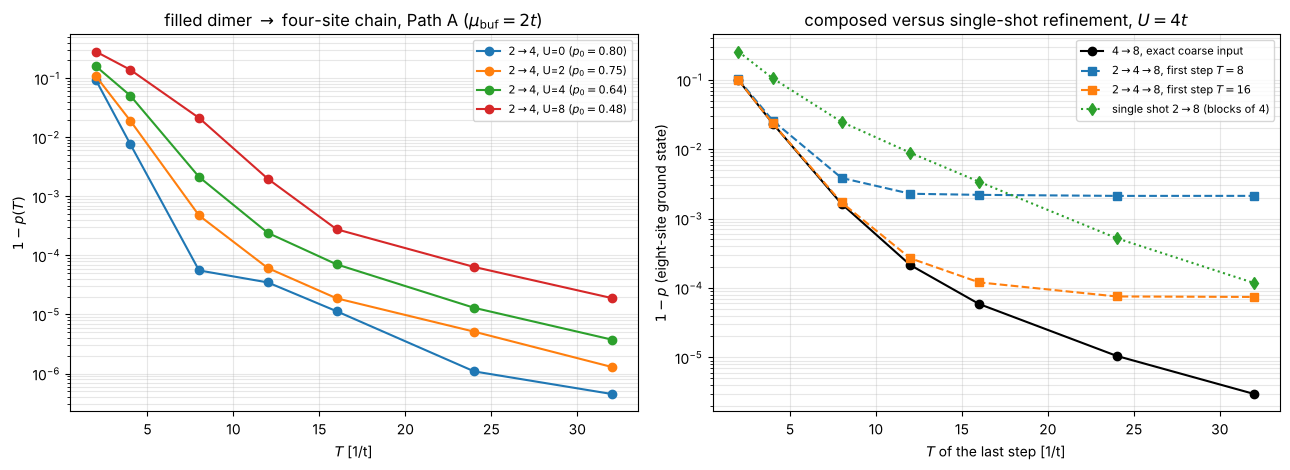

In [6]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

Ts5 = np.array([2, 4, 8, 12, 16, 24, 32])
print("filled dimer 2 -> 4, (2,2), Path A with mu_buf = 2:")
print(f"{'U/t':>4s} {'E_low':>7s} {'E_high':>8s} {'p0':>6s} {'Delta':>6s} {'D_eff':>6s} {'min gap':>8s} | " + " ".join(f"p({T})" for T in Ts5))
dimer = {}
for U in Us:
    (Nc, bc), (Nf2, bf2), blocks2, intra2 = hb.refine_chain(2)
    Hf, _ = hb.H_hubbard(Nf2, bf2, 2, 2, U); Hd = Hf.toarray(); wf, Vf = np.linalg.eigh(Hd)
    P = hb.prolong(Nc, Nf2, blocks2, 2, 2); ps = hb.prolonged_state(Hf, P)
    Deff, c2 = hb.effective_gap(ps["Phi0"], wf, Vf)
    Hle, Hhs = hb.path_A(Hd, ps["Hl"], P, ps["El"] + 2.0)
    ov, eigs = hb.refine_overlaps(ps["Phi0"], Hle, Hhs, Ts5, Vf[:, 0], MSL)
    s, W = hb.path_gap(Hle, Hhs, 21)
    dimer[U] = dict(E_low=ps["El"], E_high=wf[0], p0=c2[0], gap=wf[1]-wf[0], Deff=Deff, ov=ov, eigs=eigs, Phi0=ps["Phi0"], Hf=Hd, wf=wf, Vf=Vf)
    print(f"{U:4.0f} {ps['El']:7.3f} {wf[0]:8.4f} {c2[0]:6.3f} {wf[1]-wf[0]:6.3f} {Deff:6.3f} {(W[:,1]-W[:,0]).min():8.3f} | " + " ".join(f"{o:.4f}" for o in ov))

# --- composed chain 2 -> 4 -> 8 with refined inputs, versus exact inputs and the single-shot 2 -> 8 ---
print("\ncomposed chain 2 -> 4 -> 8 (refined input at every step, mu from the variational coarse energy), U = 4:")
U = 4.0
composed = {}
for T1 in (8, 16):
    psi4 = hb.evolve(dimer[U]["Phi0"], dimer[U]["eigs"], T1)              # refined 4-site state after T1
    r = chain48[U]; Hl4 = r["Hl"]
    # express psi4 in the coarse (4-site) sector: it IS a 4-site sector vector (dim 36)
    El_var = float(np.real(np.vdot(psi4, Hl4 @ psi4)))
    Phi0 = r["P"] @ psi4
    Hle, Hhs = hb.path_A(r["Hf"], Hl4, r["P"], El_var + 2.0)
    ov, eigs_c = hb.refine_overlaps(Phi0, Hle, Hhs, Ts5, r["Vf"][:, 0], MSL)
    composed[T1] = dict(ov=ov, psi8=hb.evolve(Phi0, eigs_c, 16)); del eigs_c
    p4 = abs(np.vdot(dimer[U]["Vf"][:, 0], psi4))**2
    print(f"  step 2->4 at T={T1}: p = {p4:.5f}, E_var = {El_var:.5f} (exact {r['E_low']:.5f}); prolonged to 8 sites: p0 = {abs(np.vdot(r['Vf'][:,0], Phi0))**2:.4f};"
          f" after 4->8: " + " ".join(f"p({T})={o:.5f}" for T, o in zip(Ts5, ov)))
print("  exact coarse input (Sec. 3):                 " + " ".join(f"p({T})={chain48[U]['paths']['A, mu_buf=2']['ov'][list(Ts).index(T)]:.5f}" for T in (8, 16, 32)))
# single shot 2 -> 8 with blocks of four fine sites
(Nc, bc), (Nf8, bf8), blocks8, intra8 = hb.refine_chain(2, b=4)
Hf8 = chain48[U]["Hf"]; wf8, Vf8 = chain48[U]["wf"], chain48[U]["Vf"]
P8 = hb.prolong(Nc, Nf8, blocks8, 2, 2); ps8 = hb.prolonged_state(Hf8, P8)
Deff8, c28 = hb.effective_gap(ps8["Phi0"], wf8, Vf8)
Hle, Hhs = hb.path_A(Hf8, ps8["Hl"], P8, ps8["El"] + 2.0)
ov28, _ = hb.refine_overlaps(ps8["Phi0"], Hle, Hhs, Ts5, Vf8[:, 0], MSL)
print(f"  single shot 2->8 (blocks of 4): E_low = {ps8['El']:.4f}, p0 = {c28[0]:.4f}, D_eff = {Deff8:.3f}; " + " ".join(f"p({T})={o:.5f}" for T, o in zip(Ts5, ov28)))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for U_, d in dimer.items():
    ax[0].semilogy(Ts5, np.maximum(1 - d["ov"], 1e-12), "o-", color=cols[U_], label=f"$2\\to4$, U={U_:.0f} ($p_0={d['p0']:.2f}$)")
ax[0].set_xlabel("$T$ [1/t]"); ax[0].set_ylabel("$1-p(T)$"); ax[0].set_title("filled dimer $\\to$ four-site chain, Path A ($\\mu_{\\rm buf}=2t$)"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3, which="both")
ax[1].semilogy(Ts5, np.maximum(1 - np.array([chain48[U]['paths']['A, mu_buf=2']['ov'][list(Ts).index(T)] for T in Ts5]), 1e-12), "k-o", label="$4\\to8$, exact coarse input")
for T1, cmp_ in composed.items():
    ax[1].semilogy(Ts5, np.maximum(1 - cmp_["ov"], 1e-12), "s--", label=f"$2\\to4\\to8$, first step $T={T1}$")
ax[1].semilogy(Ts5, np.maximum(1 - ov28, 1e-12), "d:", label="single shot $2\\to8$ (blocks of 4)")
ax[1].set_xlabel("$T$ of the last step [1/t]"); ax[1].set_ylabel("$1-p$ (eight-site ground state)"); ax[1].set_title("composed versus single-shot refinement, $U=4t$"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()


---
## 6&nbsp; Eight to sixteen sites

The $784\to14\,400$-dimensional step is handled with ARPACK for the reference and a sparse Krylov
exponential for the slice propagation (48 slices).  The effective gap is read off from the lowest
forty eigenstates of the fine sector.

In [7]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

from scipy.sparse.linalg import eigsh
from scipy.sparse import csr_matrix, identity
t0 = time.time()
(Nc, bc), (Nf16, bf16), blocks16, intra16 = hb.refine_chain(8)
U = 4.0
Hf16, _ = hb.H_hubbard(Nf16, bf16, 2, 2, U)
w16, V16 = eigsh(Hf16, k=40, which="SA", tol=1e-10); o = np.argsort(w16); w16, V16 = w16[o], V16[:, o]
P16 = hb.prolong(Nc, Nf16, blocks16, 2, 2, sparse=True); ps16 = hb.prolonged_state(Hf16, P16)
Deff16, c216 = hb.effective_gap(ps16["Phi0"], w16, V16)
S16 = hb.total_spin(V16[:, 0], Nf16, 2, 2)[1]
print(f"chain 8->16, (2,2), U={U:.0f}: dims {ps16['Hl'].shape[0]} -> {Hf16.shape[0]}; E_low = {ps16['El']:.6f}, E_high = {w16[0]:.6f}, "
      f"p0 = {c216[0]:.4f}, sector gap = {w16[1]-w16[0]:.4f}, D_eff = {Deff16:.4f} (S of the ground state: {S16:.0f})  [{time.time()-t0:.0f} s]")
print("  excitations with weight > 1e-10 among the lowest 40: " + ", ".join(f"{w16[k]-w16[0]:.3f} ({c216[k]:.1e})" for k in range(1, 40) if c216[k] > 1e-10))
mu = ps16["El"] + 2.0
Hle16 = P16 @ csr_matrix(ps16["Hl"] - mu*np.eye(len(ps16["Hl"]))) @ P16.T; Hhs16 = Hf16 - mu*identity(Hf16.shape[0])
res816 = {}
for T in (8, 16, 32):
    psi = hb.refine_sparse(ps16["Phi0"], Hle16, Hhs16, float(T), M=48)
    res816[T] = abs(np.vdot(V16[:, 0], psi))**2
    print(f"  Path A (mu_buf=2), T={T:2d}: p = {res816[T]:.6f}   [{time.time()-t0:.0f} s]")
# composed 2->4->8->16: the refined 8-site state (T=16 at each step) as input
psi8 = composed[16]["psi8"]                      # 2->4 (T=16) then 4->8 (T=16), both with variational shifts
El8 = float(np.real(np.vdot(psi8, ps16["Hl"] @ psi8)))
Phi0c = np.asarray(P16 @ psi8).ravel()
Hle16c = P16 @ csr_matrix(ps16["Hl"] - (El8+2.0)*np.eye(len(ps16["Hl"]))) @ P16.T; Hhs16c = Hf16 - (El8+2.0)*identity(Hf16.shape[0])
psi16 = hb.refine_sparse(Phi0c, Hle16c, Hhs16c, 16.0, M=48)
print(f"  composed 2->4->8->16 (T=16 per step, refined inputs): p(8-site input) = {abs(np.vdot(chain48[U]['Vf'][:,0], psi8))**2:.5f}, "
      f"prolonged p0 = {abs(np.vdot(V16[:,0], Phi0c))**2:.4f}, final p = {abs(np.vdot(V16[:,0], psi16))**2:.5f}   [{time.time()-t0:.0f} s]")


chain 8->16, (2,2), U=4: dims 784 -> 14400; E_low = -6.817213, E_high = -7.209813, p0 = 0.8692, sector gap = 0.0510, D_eff = 0.1379 (S of the ground state: 0)  [1 s]
  excitations with weight > 1e-10 among the lowest 40: 0.138 (9.9e-05), 0.415 (7.7e-04), 0.505 (1.2e-02), 0.608 (1.3e-04), 0.633 (9.1e-04), 0.700 (9.9e-05), 0.826 (2.4e-05), 0.857 (8.9e-04)


  Path A (mu_buf=2), T= 8: p = 0.992374   [5 s]


  Path A (mu_buf=2), T=16: p = 0.999313   [10 s]


  Path A (mu_buf=2), T=32: p = 0.999946   [17 s]


  composed 2->4->8->16 (T=16 per step, refined inputs): p(8-site input) = 0.99988, prolonged p0 = 0.8692, final p = 0.99923   [22 s]


---
## 7&nbsp; Two dimensions: the plaquette and the wrong symmetry sector

For the square lattice the first step is $2\times2\to4\times4$ with $2\times2$ plaquettes as blocks
($b=4$, Galerkin parameters $t/2$, $U/4$).  Besides $\mathbf S^2$ the path conserves the point group
$C_{4v}$ of the open square; we project every state on the five irreps with the character
formula $w_\Gamma=(d_\Gamma/8)\sum_g\chi_\Gamma(g)^*\langle\psi|g|\psi\rangle$, the group elements
being fermionic site permutations in the sector basis.

In [8]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

from scipy.sparse.linalg import eigsh
from scipy.sparse import csr_matrix, identity
t0 = time.time()
(Nc, bc), (Nf4, bf4), blocks4, intra4 = hb.refine_square(2)
Ts7 = np.array([4, 8, 16, 32])
print("plaquette 2x2 -> 4x4, (1,1), Path A with mu_buf = 2:")
print(f"{'U/t':>4s} {'E_low':>8s} {'E_high':>8s} {'p0':>6s} {'Delta':>6s} {'D_eff':>6s} {'irrep(coarse gs)':>16s} {'irrep(fine gs)':>14s} | " + " ".join(f"p({T})" for T in Ts7))
sq11 = {}
for U in (0.0, 4.0, 8.0):
    Hf, _ = hb.H_hubbard(Nf4, bf4, 1, 1, U); Hd = Hf.toarray(); wf, Vf = np.linalg.eigh(Hd)
    P = hb.prolong(Nc, Nf4, blocks4, 1, 1); ps = hb.prolonged_state(Hf, P)
    Deff, c2 = hb.effective_gap(ps["Phi0"], wf, Vf)
    Hle, Hhs = hb.path_A(Hd, ps["Hl"], P, ps["El"] + 2.0)
    ov, _ = hb.refine_overlaps(ps["Phi0"], Hle, Hhs, Ts7, Vf[:, 0], MSL)
    ic = hb.c4v_irrep(ps["Vl"][:, 0], 2, 1, 1); i_f = hb.c4v_irrep(Vf[:, 0], 4, 1, 1)
    sq11[U] = dict(E_low=ps["El"], E_high=wf[0], p0=c2[0], gap=wf[1]-wf[0], Deff=Deff, ov=ov)
    print(f"{U:4.0f} {ps['El']:8.4f} {wf[0]:8.4f} {c2[0]:6.3f} {wf[1]-wf[0]:6.3f} {Deff:6.3f} {ic[0]+f' ({ic[1]:.2f})':>16s} {i_f[0]+f' ({i_f[1]:.2f})':>14s} | " + " ".join(f"{o:.5f}" for o in ov))

print(f"\nplaquette 2x2 -> 4x4, (2,2): coarse levels and the fine ground state, labeled by (C4v irrep, S)   [{time.time()-t0:.0f} s]")
sq22 = {}
Uscan = (0.0, 1.0, 2.0, 4.0, 6.0, 8.0)
for U in Uscan:
    Hf, _ = hb.H_hubbard(Nf4, bf4, 2, 2, U)
    w, V = eigsh(Hf, k=30, which="SA", tol=1e-10); o = np.argsort(w); w, V = w[o], V[:, o]
    P = hb.prolong(Nc, Nf4, blocks4, 2, 2, sparse=True); ps = hb.prolonged_state(Hf, P)
    lab_c = [(hb.c4v_irrep(ps["Vl"][:, k], 2, 2, 2)[0], int(round(hb.total_spin(ps["Vl"][:, k], Nc, 2, 2)[1]))) for k in range(6)]
    lab_f = [(hb.c4v_irrep(V[:, k], 4, 2, 2)[0], int(round(hb.total_spin(V[:, k], Nf4, 2, 2)[1]))) for k in range(4)]
    ovl = np.abs(np.asarray((P @ ps["Vl"]).T @ V[:, 0]).ravel())**2
    sq22[U] = dict(wl=ps["wl"], wf=w, lab_c=lab_c, lab_f=lab_f, ovl=ovl, ps=ps, P=P, V=V, Hf=Hf)
    print(f"  U={U:.0f}: coarse E = " + ", ".join(f"{e:.4f} {l}" for e, l in zip(ps["wl"][:4], lab_c[:4]))
          + f" | fine E_0 = {w[0]:.4f} {lab_f[0]}, gap {w[1]-w[0]:.4f} (E_1 {lab_f[1]}) | weight of the fine g.s. on the coarse states: "
          + ", ".join(f"{x:.4f}" for x in ovl[:4]) + f" (all 36: {ovl.sum():.4f})")


plaquette 2x2 -> 4x4, (1,1), Path A with mu_buf = 2:
 U/t    E_low   E_high     p0  Delta  D_eff irrep(coarse gs) irrep(fine gs) | p(4) p(8) p(16) p(32)


   0  -6.0000  -6.4721  0.805  1.000  2.236        A1 (1.00)      A1 (1.00) | 0.99233 0.99994 0.99999 1.00000


   4  -5.8136  -6.2638  0.840  0.792  2.096        A1 (1.00)      A1 (1.00) | 0.99475 0.99985 0.99999 1.00000


   8  -5.7093  -6.1833  0.845  0.711  2.129        A1 (1.00)      A1 (1.00) | 0.99485 0.99977 0.99998 1.00000

plaquette 2x2 -> 4x4, (2,2): coarse levels and the fine ground state, labeled by (C4v irrep, S)   [2 s]


  U=0: coarse E = -10.0000 ('A1', 0), -10.0000 ('B2', 1), -10.0000 ('A2', 1), -10.0000 ('B1', 0) | fine E_0 = -10.9443 ('B1', 0), gap 0.0000 (E_1 ('B2', 0)) | weight of the fine g.s. on the coarse states: 0.0076, 0.0037, 0.0015, 0.6352 (all 36: 0.6480)


  U=1: coarse E = -9.8245 ('B1', 0), -9.8176 ('A2', 1), -9.7010 ('A1', 0), -9.6921 ('B2', 0) | fine E_0 = -10.7601 ('A2', 1), gap 0.0390 (E_1 ('B1', 0)) | weight of the fine g.s. on the coarse states: 0.0000, 0.6547, 0.0000, 0.0000 (all 36: 0.6549)


  U=2: coarse E = -9.6704 ('B1', 0), -9.6465 ('A2', 1), -9.4319 ('A1', 0), -9.3926 ('B2', 0) | fine E_0 = -10.6182 ('A2', 1), gap 0.0631 (E_1 ('B1', 0)) | weight of the fine g.s. on the coarse states: 0.0000, 0.6561, 0.0000, 0.0000 (all 36: 0.6570)


  U=4: coarse E = -9.4142 ('B1', 0), -9.3429 ('A2', 1), -9.0000 ('A1', 0), -8.8136 ('B2', 0) | fine E_0 = -10.4197 ('A2', 1), gap 0.0899 (E_1 ('B1', 0)) | weight of the fine g.s. on the coarse states: 0.0000, 0.6472, 0.0000, 0.0000 (all 36: 0.6545)


  U=6: coarse E = -9.2122 ('B1', 0), -9.0957 ('A2', 1), -8.7122 ('A1', 0), -8.5000 ('E', 1) | fine E_0 = -10.2907 ('A2', 1), gap 0.1040 (E_1 ('B1', 0)) | weight of the fine g.s. on the coarse states: 0.0000, 0.6258, 0.0000, 0.0000 (all 36: 0.6491)


  U=8: coarse E = -9.0514 ('B1', 0), -8.9032 ('A2', 1), -8.5341 ('A1', 0), -8.4142 ('E', 1) | fine E_0 = -10.2018 ('A2', 1), gap 0.1126 (E_1 ('B1', 0)) | weight of the fine g.s. on the coarse states: 0.0000, 0.5963, 0.0000, 0.0000 (all 36: 0.6436)


coarse state #1 (('A2', 1)), E = -9.3429, 0.0713 above the coarse g.s. (('B1', 0)); p0 = 0.6472; D_eff (lowest 30) = 1.7713 vs sector gap 0.0899


  Path A from the (A2, S=1) coarse state, T= 8: p = 0.999444


  Path A from the (A2, S=1) coarse state, T=16: p = 0.999971


  Path A from the (A2, S=1) coarse state, T=32: p = 0.999986


  Path A from the coarse ground state (('B1', 0)), T=16: p = 3.8e-26 (zero: wrong sector)


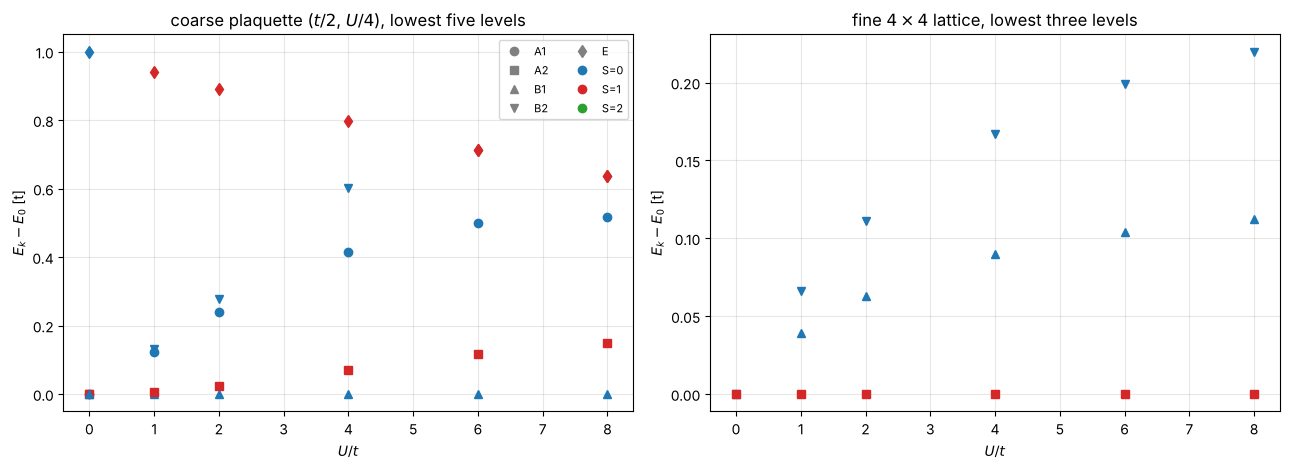

In [9]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

# --- refine the coarse state in the target's symmetry sector (the lowest coarse (A2, S=1) state), U = 4 ---
U = 4.0; d = sq22[U]
kA2 = next(k for k, l in enumerate(d["lab_c"]) if l == d["lab_f"][0])
Phi0 = np.asarray(d["P"] @ d["ps"]["Vl"][:, kA2]).ravel(); El = d["wl"][kA2]
Deff22, c2 = hb.effective_gap(Phi0, d["wf"], d["V"])
print(f"coarse state #{kA2} ({d['lab_c'][kA2]}), E = {El:.4f}, {El - d['wl'][0]:.4f} above the coarse g.s. ({d['lab_c'][0]}); p0 = {c2[0]:.4f}; "
      f"D_eff (lowest 30) = {Deff22:.4f} vs sector gap {d['wf'][1]-d['wf'][0]:.4f}")
Hle = d["P"] @ csr_matrix(d["ps"]["Hl"] - (El+2.0)*np.eye(36)) @ d["P"].T; Hhs = d["Hf"] - (El+2.0)*identity(d["Hf"].shape[0])
res22 = {}
for T in (8, 16, 32):
    psi = hb.refine_sparse(Phi0, Hle, Hhs, float(T), M=48)
    res22[T] = abs(np.vdot(d["V"][:, 0], psi))**2
    print(f"  Path A from the (A2, S=1) coarse state, T={T:2d}: p = {res22[T]:.6f}")
psi = hb.refine_sparse(np.asarray(d["P"] @ d["ps"]["Vl"][:, 0]).ravel(), Hle, Hhs, 16.0, M=48)
print(f"  Path A from the coarse ground state ({d['lab_c'][0]}), T=16: p = {abs(np.vdot(d['V'][:,0], psi))**2:.1e} (zero: wrong sector)")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
mk = {"A1": "o", "A2": "s", "B1": "^", "B2": "v", "E": "d"}; spc = {0: "C0", 1: "C3", 2: "C2"}
for U_, d_ in sq22.items():
    for k in range(5):
        ax[0].plot(U_, d_["wl"][k] - d_["wl"][0], mk[d_["lab_c"][k][0]], color=spc[d_["lab_c"][k][1]], ms=6)
    for k in range(3):
        ax[1].plot(U_, d_["wf"][k] - d_["wf"][0], mk[d_["lab_f"][k][0]], color=spc[d_["lab_f"][k][1]], ms=6)
for a, ttl in zip(ax, ("coarse plaquette ($t/2$, $U/4$), lowest five levels", "fine $4\\times4$ lattice, lowest three levels")):
    a.set_xlabel("$U/t$"); a.set_ylabel("$E_k-E_0$ [t]"); a.set_title(ttl); a.grid(alpha=0.3)
from matplotlib.lines import Line2D
h = [Line2D([], [], marker=m, color="gray", ls="", label=irr) for irr, m in mk.items()] + [Line2D([], [], marker="o", color=c, ls="", label=f"S={s}") for s, c in spc.items()]
ax[0].legend(handles=h, fontsize=8, ncol=2)
plt.tight_layout(); plt.show()


The half-filled coarse plaquette has a $B_1$ singlet ground state at every $U>0$, with the
$A_2$ triplet close above it; the dilute fine lattice (four electrons on sixteen sites, open
boundaries) has an $(A_2,S=1)$ ground state for all $U>0$ studied.  The prolongation conserves both
$\mathbf S^2$ and $C_{4v}$, so the coarse ground state has exactly zero weight on the fine ground
state and nothing to refine or filter; the lowest coarse state *in the target's sector* carries
weight $0.65$ and refines to $p>0.9999$ at $T=16/t$ despite a sector gap below $0.1t$.

---
## 8&nbsp; The rodeo filter

The filter is that of papers I and II: $M$ cycles of controlled $e^{-iH_{\rm high}t_k}$ with the
phase $e^{iE_{\rm obj}t_k}$, Gaussian times of width $\sigma$, post-selection on the ancilla.  For
$E_{\rm obj}=E_0$ the ensemble infidelity of the accepted runs is exactly
$1-\mathcal F_M=\sum_{k\ne0}|c_k|^2q_k^M/(p+\sum_{k\ne0}|c_k|^2q_k^M)$ with
$q_k=\tfrac12(1+e^{-(E_k-E_0)^2\sigma^2/2})$, which we evaluate from the ED spectrum.  The width is
set by the symmetry-protected gap, $\sigma=5/\Delta_{\rm eff}$.  Inputs: the prolonged state, the
Path-A state at $T=8$ and $16$, the Path-B state at its ceiling, and the fine-chain UCCSD state of
Section 9 (computed here so that the figure is complete).

chain 4->8 (2,2), exact ensemble rodeo with sigma = 5/D_eff   [4 s]

U=0, sigma=5.69/t:  input (p)            1-F_M for M=1,2,4,6,10        acceptance M=2, 6
   prolonged                    (0.77733)   1.3e-01 6.7e-02 1.8e-02 4.5e-03 2.8e-04    0.8330 0.7808
   Path A, T=8                  (0.99718)   1.4e-03 7.1e-04 1.8e-04 4.4e-05 2.8e-06    0.9979 0.9972
   Path A, T=16                 (0.99997)   1.7e-05 8.6e-06 2.2e-06 5.4e-07 3.4e-08    1.0000 1.0000
   Path B ($\Lambda=16$), T=32  (0.99838)   8.1e-04 4.1e-04 1.0e-04 2.5e-05 1.6e-06    0.9988 0.9984
   UCCSD (8 sites)              (1.00000)   3.2e-30 1.6e-30 4.1e-31 1.0e-31 6.6e-33    1.0000 1.0000

U=2, sigma=6.41/t:  input (p)            1-F_M for M=1,2,4,6,10        acceptance M=2, 6
   prolonged                    (0.81388)   1.0e-01 5.4e-02 1.4e-02 3.6e-03 2.2e-04    0.8604 0.8168
   Path A, T=8                  (0.99876)   6.2e-04 3.1e-04 7.8e-05 1.9e-05 1.2e-06    0.9991 0.9988
   Path A, T=16                 (0.99996)   1

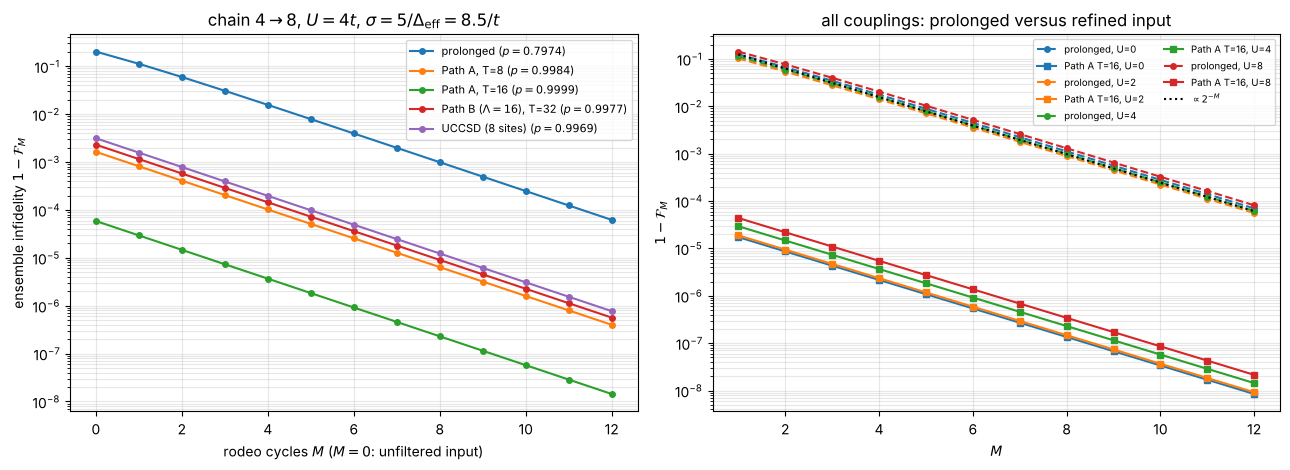

In [10]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

Ms = np.arange(1, 13)
rodeo48 = {}
t0 = time.time()
ucc_fine = {}
for U in Us:
    r = chain48[U]; sig = 5.0/r["Deff"]
    inputs = {"prolonged": r["Phi0"].astype(complex),
              "Path A, T=8": r["paths"]["A, mu_buf=2"]["states"][8],
              "Path A, T=16": r["paths"]["A, mu_buf=2"]["states"][16],
              "Path B ($\\Lambda=16$), T=32": r["paths"]["B, Lambda=16"]["states"][32]}
    uc = hb.uccsd_hubbard(8, hb.chain(8)[1], 2, 2, U, maxiter=400, H=r["Hf"])
    ucc_fine[U] = uc; inputs["UCCSD (8 sites)"] = uc["psi"]
    rodeo48[U] = dict(sigma=sig, res={})
    for name, v in inputs.items():
        inf, acc = hb.rodeo_infidelity(v, r["wf"], r["Vf"], Ms, sig)
        rodeo48[U]["res"][name] = dict(p=abs(np.vdot(r["Vf"][:, 0], v))**2, inf=inf, acc=acc)
print(f"chain 4->8 (2,2), exact ensemble rodeo with sigma = 5/D_eff   [{time.time()-t0:.0f} s]")
for U, d in rodeo48.items():
    print(f"\nU={U:.0f}, sigma={d['sigma']:.2f}/t:  input (p)            1-F_M for M=1,2,4,6,10        acceptance M=2, 6")
    for name, v in d["res"].items():
        print(f"   {name:28s} ({v['p']:.5f})   " + " ".join(f"{v['inf'][m-1]:.1e}" for m in (1, 2, 4, 6, 10)) + f"    {v['acc'][1]:.4f} {v['acc'][5]:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
U = 4.0; d = rodeo48[U]
for name, v in d["res"].items():
    ax[0].semilogy(np.concatenate([[0], Ms]), np.concatenate([[1 - v["p"]], v["inf"]]), "o-", ms=4, label=f"{name} ($p={v['p']:.4f}$)")
ax[0].set_xlabel("rodeo cycles $M$ ($M=0$: unfiltered input)"); ax[0].set_ylabel("ensemble infidelity $1-\\mathcal{F}_M$")
ax[0].set_title(f"chain $4\\to8$, $U=4t$, $\\sigma=5/\\Delta_{{\\rm eff}}={d['sigma']:.1f}/t$"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3, which="both")
for U_, d_ in rodeo48.items():
    ax[1].semilogy(Ms, d_["res"]["prolonged"]["inf"], "o--", color=cols[U_], ms=4, label=f"prolonged, U={U_:.0f}")
    ax[1].semilogy(Ms, d_["res"]["Path A, T=16"]["inf"], "s-", color=cols[U_], ms=4, label=f"Path A T=16, U={U_:.0f}")
ax[1].semilogy(Ms, 0.25*2.0**(-Ms.astype(float)), "k:", label="$\\propto2^{-M}$")
ax[1].set_xlabel("$M$"); ax[1].set_ylabel("$1-\\mathcal{F}_M$"); ax[1].set_title("all couplings: prolonged versus refined input"); ax[1].legend(fontsize=7, ncol=2); ax[1].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()


---
## 9&nbsp; The UCCSD comparator

As in paper I we compare the pipeline with a variational preparation.  The sector-level UCCSD of
`pairinglib.hubbard` uses the free-fermion orbitals as the Hartree–Fock reference, a spin-resolved
pool of singles and doubles applied as a product of exponentials in a fixed order, and the exact
adjoint gradient; it is exact for the ansatz it simulates.  On a device the reference and the
excitations live on the site register after a Givens network, and the circuit cost is counted with
the Pauli-rotation primitive of paper I.  Two uses: (i) the **coarse** solver on the four-site chain
(8 qubits), whose state is then prolonged and refined — the analogue of the $3\to4$ chain of paper
I; (ii) the **fine** solver on the eight-site chain (16 qubits) as the direct competitor.

In [11]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

print(f"{'U/t':>4s} | {'coarse L=4: E_HF':>16s} {'E_UCCSD':>9s} {'E_FCI':>9s} {'1-F':>8s} {'params':>6s} {'CNOT':>5s} | {'fine L=8: E_HF':>14s} {'E_UCCSD':>9s} {'E_FCI':>9s} {'1-F':>8s} {'params':>6s} {'CNOT':>5s}")
ucc_coarse = {}
for U in Us:
    r = chain48[U]
    Hc = hb.H_hubbard(4, hb.chain(4)[1], 2, 2, U/2, t=0.5)[0].toarray() - 4.0*np.eye(36)   # the Galerkin coarse model
    wc, Vc = np.linalg.eigh(Hc)
    uc = hb.uccsd_hubbard(4, hb.chain(4)[1], 2, 2, U/2, t=0.5, maxiter=400, H=Hc)
    ucc_coarse[U] = uc
    cc = hb.uccsd_cnots(4, uc["singles"], uc["doubles"]); cf = hb.uccsd_cnots(8, ucc_fine[U]["singles"], ucc_fine[U]["doubles"])
    uf = ucc_fine[U]
    print(f"{U:4.0f} | {uc['E_hf']:16.5f} {uc['E']:9.5f} {wc[0]:9.5f} {1-abs(np.vdot(Vc[:,0], uc['psi']))**2:8.1e} {uc['n_params']:6d} {cc['total']:5d} | "
          f"{uf['E_hf']:14.5f} {uf['E']:9.5f} {r['E_high']:9.5f} {1-abs(np.vdot(r['Vf'][:,0], uf['psi']))**2:8.1e} {uf['n_params']:6d} {cf['total']:5d}")
print("(CNOT: Givens network to the orbital basis + Pauli-rotation ladders of the excitations, block JW ordering)")

print("\nrefining the UCCSD coarse state (4 sites) to 8 sites, Path A with mu from the variational coarse energy, versus the exact coarse state:")
ucc_refined = {}
for U in Us:
    r = chain48[U]; uc = ucc_coarse[U]
    psi_low = uc["psi"]; El_var = uc["E"]
    Phi0 = r["P"] @ psi_low
    Hle, Hhs = hb.path_A(r["Hf"], r["Hl"], r["P"], El_var + 2.0)
    ov, eigs = hb.refine_overlaps(Phi0, Hle, Hhs, Ts, r["Vf"][:, 0], MSL)
    ucc_refined[U] = dict(ov=ov, Phi0=Phi0, state16=hb.evolve(Phi0, eigs, 16)); del eigs
    print(f"  U={U:.0f}: p0 = {abs(np.vdot(r['Vf'][:,0], Phi0))**2:.5f} (exact input {r['p0']:.5f});  " + "  ".join(f"p({T})={ov[list(Ts).index(T)]:.5f}" for T in (8, 16, 32))
          + "   [exact input: " + " ".join(f"{r['paths']['A, mu_buf=2']['ov'][list(Ts).index(T)]:.5f}" for T in (8, 16, 32)) + "]")


 U/t | coarse L=4: E_HF   E_UCCSD     E_FCI      1-F params  CNOT | fine L=8: E_HF   E_UCCSD     E_FCI      1-F params  CNOT
   0 |         -6.23607  -6.23607  -6.23607  6.7e-16     26  1720 |       -6.82295  -6.82295  -6.82295  1.8e-15    198 30864
   2 |         -5.23607  -5.43744  -5.43797  1.8e-04     26  1720 |       -5.71184  -6.02962  -6.03209  4.7e-04    198 30864
   4 |         -4.23607  -4.96957  -4.97657  3.3e-03     26  1720 |       -4.60073  -5.61876  -5.63443  3.1e-03    198 30864
   8 |         -2.23607  -4.51765  -4.55859  1.7e-02     26  1720 |       -2.37850  -5.22167  -5.27797  1.2e-02    198 30864
(CNOT: Givens network to the orbital basis + Pauli-rotation ladders of the excitations, block JW ordering)

refining the UCCSD coarse state (4 sites) to 8 sites, Path A with mu from the variational coarse energy, versus the exact coarse state:


  U=0: p0 = 0.77733 (exact input 0.77733);  p(8)=0.99718  p(16)=0.99997  p(32)=1.00000   [exact input: 0.99718 0.99997 1.00000]


  U=2: p0 = 0.81405 (exact input 0.81388);  p(8)=0.99856  p(16)=0.99977  p(32)=0.99982   [exact input: 0.99876 0.99996 1.00000]


  U=4: p0 = 0.79991 (exact input 0.79741);  p(8)=0.99444  p(16)=0.99669  p(32)=0.99675   [exact input: 0.99837 0.99994 1.00000]


  U=8: p0 = 0.75667 (exact input 0.75007);  p(8)=0.98046  p(16)=0.98234  p(32)=0.98277   [exact input: 0.99761 0.99991 1.00000]


---
## 10&nbsp; Circuit level: Pauli structure, Trotterized refinement and gate budgets

In the block Jordan–Wigner ordering an open chain of $L_f$ sites on $2L_f$ qubits has
$4(L_f-1)$ hopping strings $\tfrac t2(X_jX_{j+1}+Y_jY_{j+1})$ of weight two, $L_f$ interaction
strings $\tfrac U4Z_jZ_{j+L_f}$ and $2L_f$ single-$Z$ terms; we verify the count on $L=4$ (8 qubits)
with the full-space Pauli decomposition of the library and count CNOTs with the primitive of paper
I (a weight-$w$ rotation costs $2(w-1)$ CNOTs; a controlled rotation two more).  The product formula
groups the bonds into two layers of disjoint bonds (each layer is a product of commuting two-qubit
blocks, realized exactly) plus the diagonal interaction.  The embedded coarse term of Path A is
the coarse Hubbard step on the bonding register conditioned on all $2N_c$ antibonding qubits being
empty; we quote its cost with the Gray-code phase-polynomial convention of paper I and with a
Toffoli-ladder decomposition.  We then (i) find the number of second-order steps that reproduces
the exact-slice overlap at $T=16$ to within $1-p_{\rm exact}$, for both paths, and (ii) feed the
same Trotterized rodeo filter (second order, $\delta t=0.25$, forty Gaussian time sets) the
prolonged, refined and UCCSD inputs and count CNOTs per accepted preparation, exactly as in Sec. V.C
of paper I.

L=4 (8 qubits): full-space decomposition -> 24 non-identity strings, max weight 2; analytic count 24 (hopping 12, ZZ 4, Z 8)
L=4 (8 qubits): 24 strings of weight <= 2; CNOTs per step: order 1 32, order 2 64, controlled order 2 160 (24 rotations)
L=8 (16 qubits): 52 strings of weight <= 2; CNOTs per step: order 1 72, order 2 144, controlled order 2 352 (52 rotations)
Path A coarse term for 4->8: 24 rotations conditioned on 8 antibonding qubits: 1088 CNOTs (Toffoli ladder) / 12272 (Gray-code phase polynomial) per application, vs 32 unconditioned
prolongation 4->8: 16 CNOTs

Trotterized refinement, T = 16, U = 4: overlap with the fine ground state (exact slices: Path A 0.999941, Path B Lambda=8 0.992393, Lambda=16 0.993156)
 n_s |  A order 1  A order 2 | B8 order 1 B8 order 2 | B16 order 1 B16 order 2


  16 |   0.014644   0.078675 |   0.001257   0.001857 |   0.000201   0.016955


  32 |   0.760642   0.934267 |   0.016447   0.018797 |   0.001611   0.003181


  64 |   0.958169   0.997456 |   0.055708   0.038400 |   0.001800   0.007547


 128 |   0.990428   0.999831 |   0.975858   0.981090 |   0.207330   0.203377


 256 |   0.997641   0.999941 |   0.986259   0.992127 |   0.991147   0.992067


 512 |   0.999382   0.999943 |   0.990929   0.992376 |   0.993274   0.993419
  (Path B8, order 1: not within 0.001 of the exact-slice overlap at n_s=512; using it)
second-order steps reproducing the exact-slice overlap within 0.001: Path A 128, Path B (Lambda=8) 256, Path B (Lambda=16) 512   [order 1: 512, 512, 512]


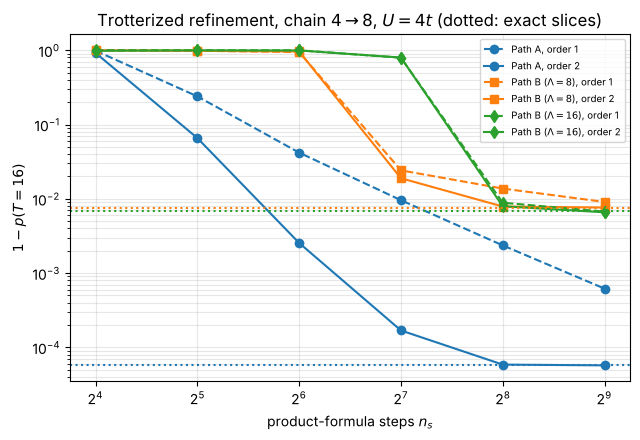

In [12]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

# --- Pauli structure and step costs ---
for L in (4, 8):
    N, bonds = hb.chain(L); pc = hb.hubbard_pauli_counts(N, bonds)
    if L == 4:
        dec = pl.pauli_decompose(hb.hubbard_full_jw(N, bonds, 4.0)); ws = [sum(c != "I" for c in s) for s in dec]
        print(f"L={L} (8 qubits): full-space decomposition -> {len(dec)-1} non-identity strings, max weight {max(ws)}; analytic count {pc['total']} (hopping {pc['hopping']}, ZZ {pc['interaction']}, Z {pc['single_Z']})")
    st1 = hb.chain_step_cnots(N, bonds, 1); st2 = hb.chain_step_cnots(N, bonds, 2); ct2 = hb.chain_step_cnots(N, bonds, 2, controlled=True)
    print(f"L={L} ({2*L} qubits): {pc['total']} strings of weight <= {pc['max_weight']}; CNOTs per step: order 1 {st1['cnots']}, order 2 {st2['cnots']}, controlled order 2 {ct2['cnots']} ({st1['rotations']} rotations)")
Nc, bc = hb.chain(4); ca = hb.conditioned_term_cnots(Nc, bc, n_controls=8)
print(f"Path A coarse term for 4->8: {ca['rotations']} rotations conditioned on 8 antibonding qubits: {ca['toffoli']} CNOTs (Toffoli ladder) / {ca['gray']} (Gray-code phase polynomial) per application, vs {ca['base']} unconditioned")
CN_PROL = 2*4*2            # Givens rotations: N_c per spin, 2 CNOTs each
print(f"prolongation 4->8: {CN_PROL} CNOTs")

# --- Trotterized refinement at T = 16, U = 4: steps needed for both paths ---
U = 4.0; r = chain48[U]; T = 16.0
Psih = r["Vf"][:, 0]
terms = hb.hubbard_terms(8, hb.chain(8)[1], 2, 2, U)          # [K_even, K_odd, D]
Kev, Kod, D = [t_.toarray() for t_ in terms]
mu = r["E_low"] + 2.0
A = r["P"] @ (r["Hl"] - mu*np.eye(36)) @ r["P"].T
p_ex = {"A": r["paths"]["A, mu_buf=2"]["ov"][list(Ts).index(16)], "B8": r["paths"]["B, Lambda=8"]["ov"][list(Ts).index(16)], "B16": r["paths"]["B, Lambda=16"]["ov"][list(Ts).index(16)]}
c2f = lambda s: np.cos(np.pi*s/2)**2; s2f = lambda s: np.sin(np.pi*s/2)**2
groupsA = [A, Kev, Kod, D - mu*np.eye(784)]; coefA = [c2f, s2f, s2f, s2f]
groupsB = [Kev, Kod, D]
coefB = {"B8": [lambda s: 1 + 8.0*np.cos(np.pi*s/2)**2, lambda s: 1.0, lambda s: 1.0],
         "B16": [lambda s: 1 + 16.0*np.cos(np.pi*s/2)**2, lambda s: 1.0, lambda s: 1.0]}
ns_list = (16, 32, 64, 128, 256, 512)
trot = {}
print(f"\nTrotterized refinement, T = {T:.0f}, U = {U:.0f}: overlap with the fine ground state (exact slices: Path A {p_ex['A']:.6f}, Path B Lambda=8 {p_ex['B8']:.6f}, Lambda=16 {p_ex['B16']:.6f})")
print(f"{'n_s':>4s} | {'A order 1':>10s} {'A order 2':>10s} | {'B8 order 1':>10s} {'B8 order 2':>10s} | {'B16 order 1':>11s} {'B16 order 2':>11s}")
for ns in ns_list:
    row = []
    for key in ("A", "B8", "B16"):
        groups, coefs = (groupsA, coefA) if key == "A" else (groupsB, coefB[key])
        for order in (1, 2):
            psi = hb.trotter_refine(r["Phi0"], groups, coefs, T, ns, order=order)
            p = abs(np.vdot(Psih, psi))**2; trot[(key, order, ns)] = p; row.append(p)
    print(f"{ns:4d} | " + " | ".join(f"{row[2*k]:10.6f} {row[2*k+1]:10.6f}" for k in range(3)))
TOL = 1e-3
def n_needed(key, order):
    for ns in ns_list:
        if abs(trot[(key, order, ns)] - p_ex[key]) <= TOL: return ns
    print(f"  (Path {key}, order {order}: not within {TOL} of the exact-slice overlap at n_s={ns_list[-1]}; using it)"); return ns_list[-1]
n_ref = {key: n_needed(key, 2) for key in ("A", "B8", "B16")}
print(f"second-order steps reproducing the exact-slice overlap within {TOL}: Path A {n_ref['A']}, Path B (Lambda=8) {n_ref['B8']}, Path B (Lambda=16) {n_ref['B16']}"
      f"   [order 1: {n_needed('A', 1)}, {n_needed('B8', 1)}, {n_needed('B16', 1)}]")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for key, order, mk_, col in (("A", 1, "o--", "C0"), ("A", 2, "o-", "C0"), ("B8", 1, "s--", "C1"), ("B8", 2, "s-", "C1"), ("B16", 1, "d--", "C2"), ("B16", 2, "d-", "C2")):
    ax.semilogy(ns_list, [max(1 - trot[(key, order, ns)], 1e-9) for ns in ns_list], mk_, color=col, label=f"Path {key.replace('B8', 'B ($\\Lambda=8$)').replace('B16', 'B ($\\Lambda=16$)')}, order {order}")
for key, col in (("A", "C0"), ("B8", "C1"), ("B16", "C2")):
    ax.axhline(1 - p_ex[key], color=col, ls=":")
ax.set_xscale("log", base=2); ax.set_xlabel("product-formula steps $n_s$"); ax.set_ylabel("$1-p(T=16)$"); ax.set_title("Trotterized refinement, chain $4\\to8$, $U=4t$ (dotted: exact slices)"); ax.legend(fontsize=7); ax.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()


Trotterized controlled evolution (second order): the fixed step is diagonalized once; the filter then projects on the
eigenvector of the step unitary closest to the ground state, whose eigenphase is what an energy scan on the device locates:


  dt =  0.25: E_eff - E_0 = +8.92e-02, infidelity floor 1-|<Psi|w>|^2 = 2.6e-03


  dt =  0.10: E_eff - E_0 = +1.35e-02, infidelity floor 1-|<Psi|w>|^2 = 5.8e-05


  dt =  0.05: E_eff - E_0 = +3.35e-03, infidelity floor 1-|<Psi|w>|^2 = 3.5e-06


operating point: dt = 0.1, E_obj = E_eff = -5.620907 (E_0 = -5.634427), sigma = 8.51; cycle times quantized to multiples of dt



chain 4->8, U=4: Trotterized rodeo (order 2, dt=0.1, sigma=8.51, 40 time sets); per-step CNOTs 144 (controlled 352); coarse term 1088/application   [1 s]
input                                               p prep CNOT | M=1: 1-F_w   acc   CNOT/acc | M=2: 1-F_w   acc   CNOT/acc | M=4: 1-F_w   acc   CNOT/acc | M=6: 1-F_w   acc   CNOT/acc
prolonged                                     0.79741        16 | 1.1e-01 0.8946    24542 | 6.0e-02 0.8482    51922 | 1.7e-02 0.8112   109156 | 4.7e-03 0.8015   154018
Path B ($\Lambda=8$) refined, T=16, n_s=256   0.99213     36880 | 3.9e-03 0.9959    59060 | 2.0e-03 0.9940    83878 | 5.9e-04 0.9926   137184 | 2.0e-04 0.9922   180398
Path B ($\Lambda=16$) refined, T=16, n_s=512  0.99342     73744 | 3.0e-03 0.9962    96045 | 1.7e-03 0.9947   120882 | 5.2e-04 0.9935   174214 | 1.9e-04 0.9932   217428
Path A refined, T=16, n_s=128                 0.99983    296976 | 1.1e-04 1.0000   318925 | 8.6e-05 1.0000   343588 | 6.4e-05 0.9999   396727 | 5.9e-05 0.999

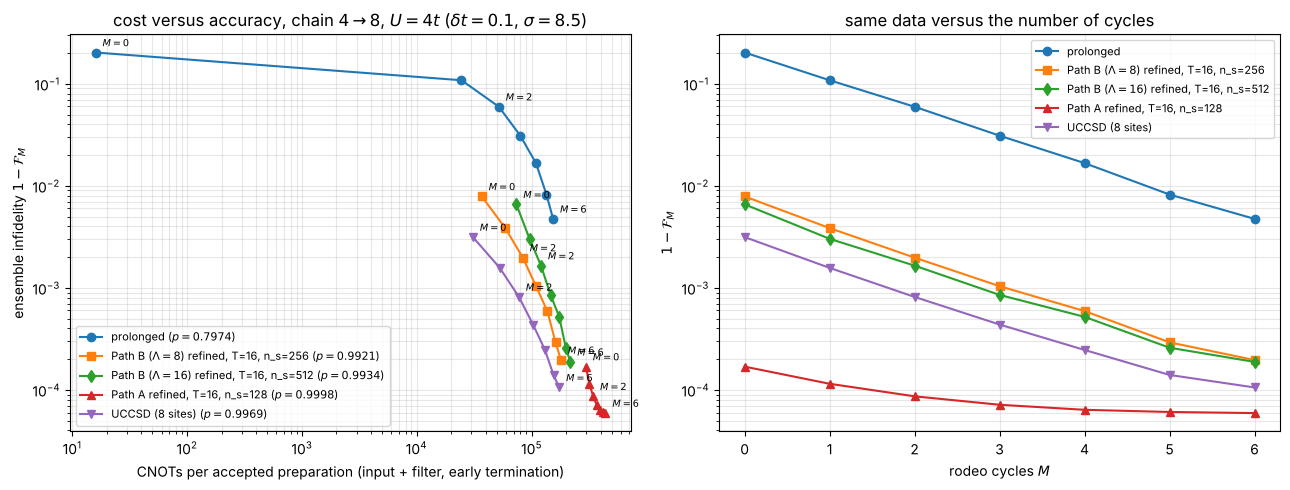

In [13]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

# --- matched-observable comparison: the same Trotterized rodeo filter on every input ---
U = 4.0; r = chain48[U]; Psih = r["Vf"][:, 0]; E0 = r["E_high"]
NSAMP, M_MAX, SEED = 40, 6, 3
SIG = rodeo48[U]["sigma"]
N8, b8 = hb.chain(8)
st2 = hb.chain_step_cnots(N8, b8, 2)["cnots"]; ct2 = hb.chain_step_cnots(N8, b8, 2, controlled=True)["cnots"]
ca = hb.conditioned_term_cnots(4, hb.chain(4)[1], n_controls=8)["toffoli"]
terms = hb.hubbard_terms(N8, b8, 2, 2, U)
print("Trotterized controlled evolution (second order): the fixed step is diagonalized once; the filter then projects on the")
print("eigenvector of the step unitary closest to the ground state, whose eigenphase is what an energy scan on the device locates:")
for dt_ in (0.25, 0.1, 0.05):
    tr_ = hb.trotter_evolution(terms, dt_, order=2, target=Psih)
    print(f"  dt = {dt_:5.2f}: E_eff - E_0 = {tr_['E_eff'] - E0:+.2e}, infidelity floor 1-|<Psi|w>|^2 = {tr_['floor']:.1e}")
DT = 0.1
tr = hb.trotter_evolution(terms, DT, order=2, target=Psih); E_obj = tr["E_eff"]
print(f"operating point: dt = {DT}, E_obj = E_eff = {E_obj:.6f} (E_0 = {E0:.6f}), sigma = {SIG:.2f}; cycle times quantized to multiples of dt")
# inputs with their preparation cost (second-order refinement with the steps found above; the coarse term twice per step)
inputs = {"prolonged": (r["Phi0"].astype(complex), CN_PROL),
          f"Path B ($\\Lambda=8$) refined, T=16, n_s={n_ref['B8']}": (hb.trotter_refine(r["Phi0"], groupsB, coefB["B8"], 16.0, n_ref["B8"], order=2), CN_PROL + n_ref["B8"]*st2),
          f"Path B ($\\Lambda=16$) refined, T=16, n_s={n_ref['B16']}": (hb.trotter_refine(r["Phi0"], groupsB, coefB["B16"], 16.0, n_ref["B16"], order=2), CN_PROL + n_ref["B16"]*st2),
          f"Path A refined, T=16, n_s={n_ref['A']}": (hb.trotter_refine(r["Phi0"], groupsA, coefA, 16.0, n_ref["A"], order=2), CN_PROL + n_ref["A"]*(st2 + 2*ca)),
          "UCCSD (8 sites)": (ucc_fine[U]["psi"], hb.uccsd_cnots(8, ucc_fine[U]["singles"], ucc_fine[U]["doubles"])["total"])}
rng = np.random.default_rng(SEED)
tsets = [np.abs(rng.normal(0.0, SIG, M_MAX)) for _ in range(NSAMP)]
cyc_cost = np.array([[tr["nsteps"](t)*ct2 for t in ts] for ts in tsets])        # CNOTs per cycle (controlled second-order steps)
rows = {}
t0 = time.time()
for name, (v0, cprep) in inputs.items():
    p = abs(np.vdot(Psih, v0))**2
    F = np.zeros((NSAMP, M_MAX)); Acc = np.zeros((NSAMP, M_MAX))
    for s_, ts in enumerate(tsets):
        F[s_], Acc[s_] = hb.rodeo_track_U(v0, tr["Ufun"], ts, E_obj, Psih, dt=DT)
    Fw = (F*Acc).sum(0)/Acc.sum(0); Am = Acc.mean(0)
    reach = np.concatenate([np.ones((NSAMP, 1)), Acc[:, :-1]], axis=1)
    cost_et = (cprep + np.cumsum(reach*cyc_cost, axis=1).mean(0))/Am
    rows[name] = dict(p=p, cprep=cprep, Fw=Fw, A=Am, cost=cost_et)
print(f"\nchain 4->8, U={U:.0f}: Trotterized rodeo (order 2, dt={DT}, sigma={SIG:.2f}, {NSAMP} time sets); per-step CNOTs {st2} (controlled {ct2}); coarse term {ca}/application   [{time.time()-t0:.0f} s]")
print(f"{'input':44s} {'p':>8s} {'prep CNOT':>9s} | " + " | ".join(f"M={m}: 1-F_w   acc   CNOT/acc" for m in (1, 2, 4, 6)))
for name, d in rows.items():
    print(f"{name:44s} {d['p']:8.5f} {d['cprep']:9d} | " + " | ".join(f"{1-d['Fw'][m-1]:.1e} {d['A'][m-1]:.4f} {d['cost'][m-1]:8.0f}" for m in (1, 2, 4, 6)))
floor = min(1 - d["Fw"][-1] for d in rows.values())
print(f"best infidelity after {M_MAX} cycles: {floor:.1e} (Trotter floor of the filter: {tr['floor']:.1e})")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
mks = ["o-", "s-", "d-", "^-", "v-"]
for (name, d), mk_ in zip(rows.items(), mks):
    inf = np.concatenate([[1 - d["p"]], 1 - d["Fw"]]); cost = np.concatenate([[d["cprep"]], d["cost"]])
    ax[0].loglog(cost, inf, mk_, label=f"{name} ($p={d['p']:.4f}$)")
    for m in (0, 2, 6): ax[0].annotate(f"$M={m}$", (cost[m], inf[m]), textcoords="offset points", xytext=(5, 4), fontsize=7)
    ax[1].semilogy(np.arange(0, M_MAX+1), inf, mk_, label=name)
ax[0].set_xlabel("CNOTs per accepted preparation (input + filter, early termination)"); ax[0].set_ylabel("ensemble infidelity $1-\\mathcal{F}_M$")
ax[0].set_title(f"cost versus accuracy, chain $4\\to8$, $U=4t$ ($\\delta t={DT}$, $\\sigma={SIG:.1f}$)"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3, which="both")
ax[1].set_xlabel("rodeo cycles $M$"); ax[1].set_ylabel("$1-\\mathcal{F}_M$"); ax[1].set_title("same data versus the number of cycles"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()


---
## 11&nbsp; Revision checks: the counted coarse term, the pruned variational comparator, the ordinary adiabatic ramp and the response norm

The assessment of paper I (October 2026) raised points that apply here as well; this section
settles them for the chain $4\to8$ at $U=4t$.  (a) The embedded coarse term of Path A contains
non-commuting coarse terms; the counted circuit does not exponentiate it as one block but as the
three conditioned coarse groups $P(D_c-\mu)P^\dagger$, $PK^c_{\rm even}P^\dagger$,
$PK^c_{\rm odd}P^\dagger$, and the Trotterized refinement is repeated at that level.  (b) The
198-parameter UCCSD of Section 9 is pruned to the operators whose amplitudes exceed $10^{-3}$ and
re-optimized, which is the demonstrated restricted ansatz that an adaptive selection would at
best find.  (c) An ordinary adiabatic ramp that switches on the interaction,
$H(s)=K+\sin^2(\pi s/2)\,U\sum_in_{i\uparrow}n_{i\downarrow}$ started from the free-fermion
determinant of the fine chain (prepared by a Givens network), is the generic preconditioning
against which the specific refinement paths must be measured.  (d) The first-order response norm
$\chi_u(s)=\sum_{n>0}|\langle n|\partial_uH|0\rangle|^2/(E_n-E_0)^2$, $u=\sin^2(\pi s/2)$, of
Path A is followed along the path for every $U$, and the digital filter's long-run state is
characterized.  (e) The matched comparison of Section 10 is repeated with the new inputs, with
$M=0$ included, with CNOTs per attempt as well as per accepted preparation, with bootstrap
uncertainties of the sampled infidelities, and with the minimum cost at three target
infidelities.

(a) Path A, T=16, U=4: exact slices p = 0.999941; second-order product formula with the coarse term as one block / split into three conditioned coarse groups:


    n_s =  64: one block 0.997456   split 0.997299


    n_s = 128: one block 0.999831   split 0.999818


    n_s = 256: one block 0.999941   split 0.999941


    n_s = 512: one block 0.999943   split 0.999943
    steps within 1e-3 of the exact-slice overlap (split groups): n_s = 128; cost 16 + 128*(144 + 2*1088) = 296976 CNOTs
(b) UCCSD (8 sites): 72 of 198 amplitudes exceed 1e-02
(b) UCCSD (8 sites): 98 of 198 amplitudes exceed 1e-03


...

    T = 16: exact 0.999885; n_s = 128 second-order steps give 0.999659; cost 112 (Givens network) + 128*144 = 18544 CNOTs
(d) first-order response norm chi_u(s) of Path A (mu_buf = 2):


    U=0: chi_u(0) = 0.375, max_s chi_u(s) = 0.375 at s = 0.00


    U=2: chi_u(0) = 0.527, max_s chi_u(s) = 0.527 at s = 0.00


    U=4: chi_u(0) = 0.715, max_s chi_u(s) = 0.715 at s = 0.00


    U=8: chi_u(0) = 0.874, max_s chi_u(s) = 0.874 at s = 0.00


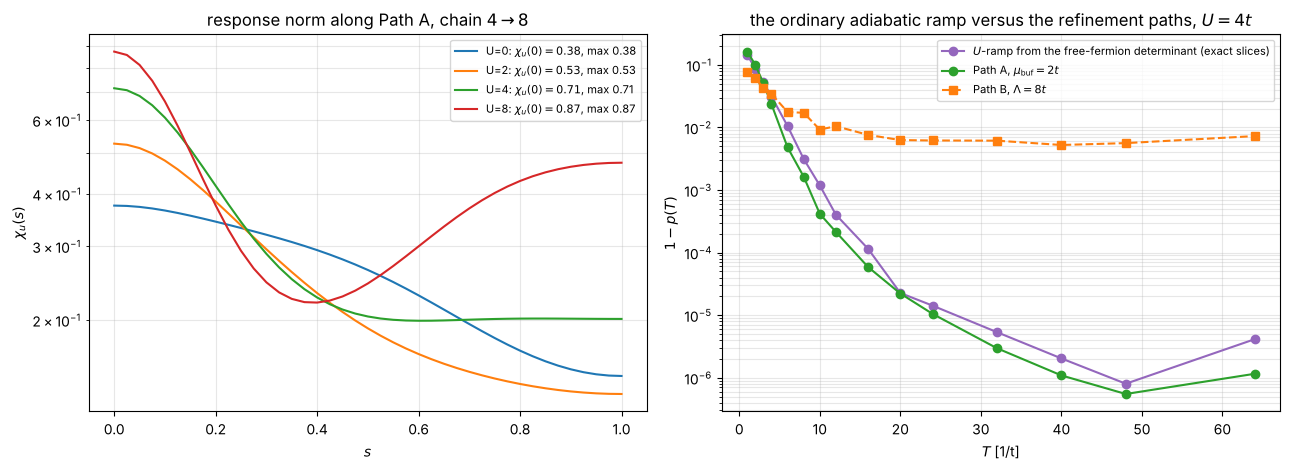

    fixed-step filter (dt = 0.1): with quantized times all cycles share the eigenvectors of the step unitary, so the long-run accepted state is its
    eigenvector closest to the ground state (infidelity floor 5.76e-05) and, with E_obj = E_eff, the long-run acceptance tends to the input weight on it rather than decaying


In [14]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

from scipy.optimize import minimize
U = 4.0; r = chain48[U]; Psih = r["Vf"][:, 0]; Hd = r["Hf"]; mu = r["E_low"] + 2.0
Kev, Kod, D = [t_.toarray() for t_ in hb.hubbard_terms(8, hb.chain(8)[1], 2, 2, U)]
c2f = lambda s: np.cos(np.pi*s/2)**2; s2f = lambda s: np.sin(np.pi*s/2)**2
# --- (a) Path A with the coarse term split into its coarse Trotter groups
tl, Ul, cst = hb.galerkin_params("chain", 1.0, U, 4)
Kc_e, Kc_o, Dc = [t_.toarray() for t_ in hb.hubbard_terms(4, hb.chain(4)[1], 2, 2, Ul, t=tl)]
A_groups = [r["P"] @ (Dc + (cst - mu)*np.eye(36)) @ r["P"].T, r["P"] @ Kc_e @ r["P"].T, r["P"] @ Kc_o @ r["P"].T]
assert abs(sum(A_groups) - r["P"] @ (r["Hl"] - mu*np.eye(36)) @ r["P"].T).max() < 1e-10
groupsA_split = A_groups + [Kev, Kod, D - mu*np.eye(784)]; coefA_split = [c2f]*3 + [s2f]*3
pA_ex = p_ex["A"]
print(f"(a) Path A, T=16, U={U:.0f}: exact slices p = {pA_ex:.6f}; second-order product formula with the coarse term as one block / split into three conditioned coarse groups:")
trotA = {}
for ns in (64, 128, 256, 512):
    p1 = abs(np.vdot(Psih, hb.trotter_refine(r["Phi0"], groupsA, coefA, 16.0, ns, order=2)))**2
    p2 = abs(np.vdot(Psih, hb.trotter_refine(r["Phi0"], groupsA_split, coefA_split, 16.0, ns, order=2)))**2
    trotA[ns] = p2; print(f"    n_s = {ns:3d}: one block {p1:.6f}   split {p2:.6f}")
nA_split = next(ns for ns in (64, 128, 256, 512) if abs(trotA[ns] - pA_ex) <= 1e-3)
ca = hb.conditioned_term_cnots(4, hb.chain(4)[1], n_controls=8)["toffoli"]; st2 = hb.chain_step_cnots(8, hb.chain(8)[1], 2)["cnots"]
print(f"    steps within 1e-3 of the exact-slice overlap (split groups): n_s = {nA_split}; cost {CN_PROL} + {nA_split}*({st2} + 2*{ca}) = {CN_PROL + nA_split*(st2 + 2*ca)} CNOTs")

# --- (b) pruned UCCSD on the fine chain
uf = ucc_fine[U]; th = np.abs(uf["theta"]); labels = uf["singles"] + uf["doubles"]
for thr in (1e-2, 1e-3):
    print(f"(b) UCCSD (8 sites): {int((th > thr).sum())} of {len(th)} amplitudes exceed {thr:.0e}")
keep = [i for i in range(len(th)) if th[i] > 1e-3]
up = hb.uccsd_hubbard(8, hb.chain(8)[1], 2, 2, U, maxiter=400, H=Hd, keep=keep, theta0=uf["theta"][keep])
cn_full = hb.uccsd_cnots(8, uf["singles"], uf["doubles"])["total"]; cn_pr = hb.uccsd_cnots(8, up["singles"], up["doubles"])["total"]
print(f"    pruned ansatz ({up['n_params']} parameters, {cn_pr} CNOTs): E = {up['E']:.6f}, 1-F = {1-abs(np.vdot(Psih, up['psi']))**2:.3e}   (full: {uf['n_params']} parameters, {cn_full} CNOTs, 1-F = {1-abs(np.vdot(Psih, uf['psi']))**2:.3e}, FCI {r['E_high']:.6f})")

# --- (c) the ordinary adiabatic ramp K -> K + U n n from the free-fermion determinant
Hfree, _ = hb.H_hubbard(8, hb.chain(8)[1], 2, 2, 0.0); w0, V0 = np.linalg.eigh(Hfree.toarray()); FF = V0[:, 0]
Deff_ff, c2ff = hb.effective_gap(FF, r["wf"], r["Vf"])
ov_r, _ = hb.refine_overlaps(FF, Hd - D, Hd, Ts, Psih, MSL)
print(f"(c) U-ramp from the free-fermion determinant: p0 = {c2ff[0]:.4f}, D_eff = {Deff_ff:.3f}; exact slices: " + " ".join(f"p({T})={o:.5f}" for T, o in zip(Ts, ov_r) if T in (4, 8, 12, 16, 24, 32)))
groupsR = [Kev, Kod, D]; coefR = [lambda s: 1.0, lambda s: 1.0, s2f]
CN_GIVENS = 2*(8*7//2)*2
ramp = {}
for T in (8, 16):
    pex = ov_r[list(Ts).index(T)]
    for ns in (16, 32, 64, 128, 256):
        pr = abs(np.vdot(Psih, hb.trotter_refine(FF, groupsR, coefR, float(T), ns, order=2)))**2
        if abs(pr - pex) <= 1e-3 or ns == 256:
            ramp[T] = (ns, pr); break
    print(f"    T = {T}: exact {pex:.6f}; n_s = {ramp[T][0]} second-order steps give {ramp[T][1]:.6f}; cost {CN_GIVENS} (Givens network) + {ramp[T][0]}*{st2} = {CN_GIVENS + ramp[T][0]*st2} CNOTs")

# --- (d) response norm along Path A for every U, and the long-run state of the fixed-step filter
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
sgrid = np.linspace(0, 1, 41)
print("(d) first-order response norm chi_u(s) of Path A (mu_buf = 2):")
for U_, r_ in chain48.items():
    mu_ = r_["E_low"] + 2.0; A_ = r_["P"] @ (r_["Hl"] - mu_*np.eye(36)) @ r_["P"].T; B_ = r_["Hf"] - mu_*np.eye(784); dHu = B_ - A_
    chi = []
    for s_ in sgrid:
        u = np.sin(np.pi*s_/2)**2; ws, Vs = np.linalg.eigh((1-u)*A_ + u*B_)
        amp = np.abs(Vs[:, 1:].T @ (dHu @ Vs[:, 0]))**2; chi.append(float(np.sum(amp/(ws[1:]-ws[0])**2)))
    ax[0].plot(sgrid, chi, color=cols[U_], label=f"U={U_:.0f}: $\\chi_u(0)={chi[0]:.2f}$, max {max(chi):.2f}")
    print(f"    U={U_:.0f}: chi_u(0) = {chi[0]:.3f}, max_s chi_u(s) = {max(chi):.3f} at s = {sgrid[int(np.argmax(chi))]:.2f}")
ax[0].set_yscale("log"); ax[0].set_xlabel("$s$"); ax[0].set_ylabel("$\\chi_u(s)$"); ax[0].set_title("response norm along Path A, chain $4\\to8$"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3, which="both")
ax[1].semilogy(Ts[1:], np.maximum(1 - ov_r[1:], 1e-12), "o-", color="C4", label="$U$-ramp from the free-fermion determinant (exact slices)")
ax[1].semilogy(Ts[1:], np.maximum(1 - r["paths"]["A, mu_buf=2"]["ov"][1:], 1e-12), "o-", color="C2", label="Path A, $\\mu_{\\rm buf}=2t$")
ax[1].semilogy(Ts[1:], np.maximum(1 - r["paths"]["B, Lambda=8"]["ov"][1:], 1e-12), "s--", color="C1", label="Path B, $\\Lambda=8t$")
ax[1].set_xlabel("$T$ [1/t]"); ax[1].set_ylabel("$1-p(T)$"); ax[1].set_title("the ordinary adiabatic ramp versus the refinement paths, $U=4t$"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()
tr_ = hb.trotter_evolution(hb.hubbard_terms(8, hb.chain(8)[1], 2, 2, U), 0.1, order=2, target=Psih)
print(f"    fixed-step filter (dt = 0.1): with quantized times all cycles share the eigenvectors of the step unitary, so the long-run accepted state is its")
print(f"    eigenvector closest to the ground state (infidelity floor {tr_['floor']:.2e}) and, with E_obj = E_eff, the long-run acceptance tends to the input weight on it rather than decaying")


chain 4->8, U=4: Trotterized rodeo (order 2, dt=0.1, sigma=8.51, E_obj = E_eff, 40 time sets; bootstrap relative std. error of the sampled infidelity in brackets)
input                                           p   prep | M=0: 1-F_w (rse)  acc  /attempt /accepted | M=2: 1-F_w (rse)  acc  /attempt /accepted | M=6: 1-F_w (rse)  acc  /attempt /accepted
prolonged                                 0.79741     16 | 2.0e-01 (  0%) 1.000       16       16 | 6.0e-02 (  7%) 0.848    46612    51922 | 4.7e-03 ( 18%) 0.801   142893   154018
free-fermion determinant                  0.78040    112 | 2.2e-01 (  0%) 1.000      112      112 | 6.6e-02 (  5%) 0.831    46708    52791 | 5.0e-03 ( 17%) 0.779   142989   155570
UCCSD pruned (98 par.)                    0.99685  15120 | 3.1e-03 (  0%) 1.000    15120    15120 | 8.2e-04 (  6%) 0.997    61716    61833 | 1.1e-04 (  7%) 0.997   157997   158198
UCCSD (198 par.)                          0.99686  30864 | 3.1e-03 (  0%) 1.000    30864    30864 | 8.1e-04 

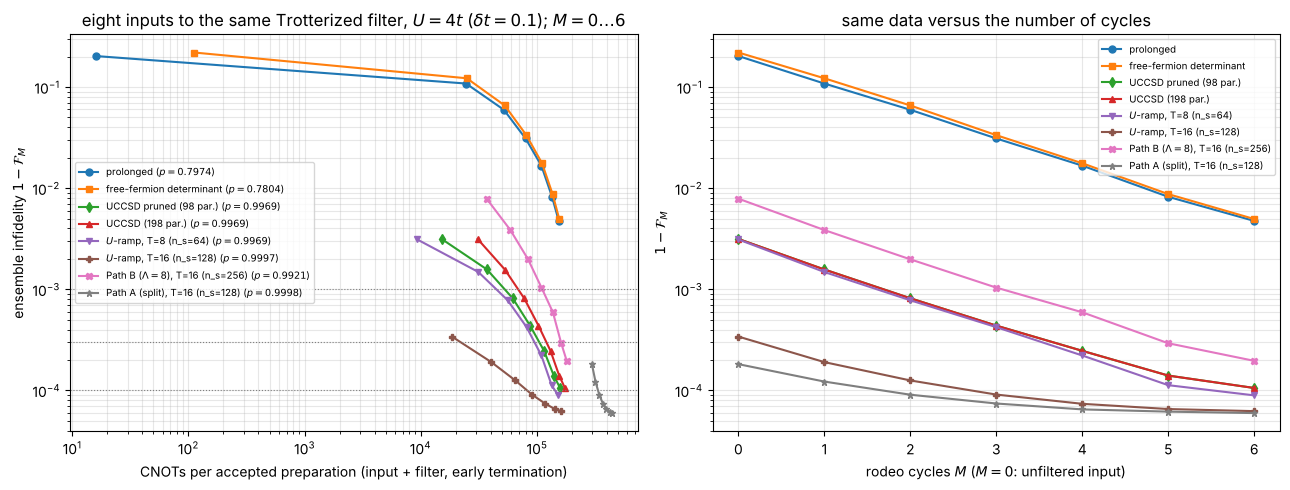

In [15]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

# --- (e) matched comparison with the new inputs: M = 0..6, per attempt and per accepted, bootstrap errors, minimum cost at targets
U = 4.0; r = chain48[U]; Psih = r["Vf"][:, 0]
inputs2 = {"prolonged": (r["Phi0"].astype(complex), CN_PROL),
           "free-fermion determinant": (FF.astype(complex), CN_GIVENS),
           f"UCCSD pruned ({up['n_params']} par.)": (up["psi"], cn_pr),
           "UCCSD (198 par.)": (ucc_fine[U]["psi"], cn_full),
           f"$U$-ramp, T=8 (n_s={ramp[8][0]})": (hb.trotter_refine(FF, groupsR, coefR, 8.0, ramp[8][0], order=2), CN_GIVENS + ramp[8][0]*st2),
           f"$U$-ramp, T=16 (n_s={ramp[16][0]})": (hb.trotter_refine(FF, groupsR, coefR, 16.0, ramp[16][0], order=2), CN_GIVENS + ramp[16][0]*st2),
           f"Path B ($\\Lambda=8$), T=16 (n_s={n_ref['B8']})": (hb.trotter_refine(r["Phi0"], groupsB, coefB["B8"], 16.0, n_ref["B8"], order=2), CN_PROL + n_ref["B8"]*st2),
           f"Path A (split), T=16 (n_s={nA_split})": (hb.trotter_refine(r["Phi0"], groupsA_split, coefA_split, 16.0, nA_split, order=2), CN_PROL + nA_split*(st2 + 2*ca))}
rng = np.random.default_rng(SEED); tsets = [np.abs(rng.normal(0.0, SIG, M_MAX)) for _ in range(NSAMP)]
cyc_cost = np.array([[tr["nsteps"](t)*ct2 for t in ts] for ts in tsets])
rows2 = {}
rngb = np.random.default_rng(5)
for name, (v0, cprep) in inputs2.items():
    p = abs(np.vdot(Psih, v0))**2
    F = np.zeros((NSAMP, M_MAX)); Acc = np.zeros((NSAMP, M_MAX))
    for s_, ts in enumerate(tsets):
        F[s_], Acc[s_] = hb.rodeo_track_U(v0, tr["Ufun"], ts, E_obj, Psih, dt=DT)
    Fw = (F*Acc).sum(0)/Acc.sum(0); Am = Acc.mean(0)
    boots = np.array([1 - ((F*Acc)[idx].sum(0)/Acc[idx].sum(0)) for idx in (rngb.integers(0, NSAMP, NSAMP) for _ in range(400))])
    rse = boots.std(0)/np.maximum(1 - Fw, 1e-30)
    reach = np.concatenate([np.ones((NSAMP, 1)), Acc[:, :-1]], axis=1)
    cost_acc = np.concatenate([[float(cprep)], (cprep + np.cumsum(reach*cyc_cost, axis=1).mean(0))/Am])
    cost_att = np.concatenate([[float(cprep)], cprep + np.cumsum(cyc_cost, axis=1).mean(0)])
    rows2[name] = dict(p=p, cprep=cprep, inf=np.concatenate([[1-p], 1-Fw]), rse=np.concatenate([[0.0], rse]), acc=np.concatenate([[1.0], Am]), cost_acc=cost_acc, cost_att=cost_att)
print(f"chain 4->8, U={U:.0f}: Trotterized rodeo (order 2, dt={DT}, sigma={SIG:.2f}, E_obj = E_eff, {NSAMP} time sets; bootstrap relative std. error of the sampled infidelity in brackets)")
print(f"{'input':40s} {'p':>8s} {'prep':>6s} | " + " | ".join(f"M={m}: 1-F_w (rse)  acc  /attempt /accepted" for m in (0, 2, 6)))
for name, d in rows2.items():
    print(f"{name:40s} {d['p']:8.5f} {d['cprep']:6d} | " + " | ".join(f"{d['inf'][m]:.1e} ({100*d['rse'][m]:3.0f}%) {d['acc'][m]:.3f} {d['cost_att'][m]:8.0f} {d['cost_acc'][m]:8.0f}" for m in (0, 2, 6)))
print(f"best infidelity after {M_MAX} cycles: {min(d['inf'][-1] for d in rows2.values()):.1e} (floor of the fixed-step filter {tr['floor']:.1e})")
print("\nfull table, M = 0..6: ensemble infidelity (bootstrap rse %) / cumulative acceptance / CNOTs per accepted preparation")
for name, d in rows2.items():
    print(f"  {name}")
    print("     1-F : " + " ".join(f"{d['inf'][m]:.2e}({100*d['rse'][m]:2.0f}%)" for m in range(M_MAX+1)))
    print("     acc : " + " ".join(f"{d['acc'][m]:12.4f}" for m in range(M_MAX+1)))
    print("     cost: " + " ".join(f"{d['cost_acc'][m]:12.0f}" for m in range(M_MAX+1)))
print("\nminimum CNOTs per accepted preparation reaching a target infidelity, per input (M = 0..6; '-' = not reached):")
TGTS = (1e-3, 3e-4, 1e-4)
print(f"{'input':40s} " + " ".join(f"{'target '+format(t,'.0e'):>22s}" for t in TGTS))
for name, d in rows2.items():
    cells_ = []
    for tgt in TGTS:
        ok = np.where(d["inf"] <= tgt)[0]
        if ok.size:
            m = ok[np.argmin(d["cost_acc"][ok])]; cells_.append(f"M={m} {d['cost_acc'][m]:8.0f} ({d['inf'][m]:.1e})")
        else: cells_.append("-")
    print(f"{name:40s} " + " ".join(f"{c:>22s}" for c in cells_))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
mks = ["o-", "s-", "d-", "^-", "v-", "P-", "X-", "*-"]
for (name, d), mk_ in zip(rows2.items(), mks):
    ax[0].loglog(d["cost_acc"], d["inf"], mk_, ms=5, label=f"{name} ($p={d['p']:.4f}$)")
    ax[1].semilogy(np.arange(0, M_MAX+1), d["inf"], mk_, ms=5, label=name)
for tgt in (1e-3, 3e-4, 1e-4): ax[0].axhline(tgt, color="gray", ls=":", lw=0.8)
ax[0].set_xlabel("CNOTs per accepted preparation (input + filter, early termination)"); ax[0].set_ylabel("ensemble infidelity $1-\\mathcal{F}_M$")
ax[0].set_title(f"eight inputs to the same Trotterized filter, $U=4t$ ($\\delta t={DT}$); $M=0\\ldots6$"); ax[0].legend(fontsize=7); ax[0].grid(alpha=0.3, which="both")
ax[1].set_xlabel("rodeo cycles $M$ ($M=0$: unfiltered input)"); ax[1].set_ylabel("$1-\\mathcal{F}_M$"); ax[1].set_title("same data versus the number of cycles"); ax[1].legend(fontsize=7); ax[1].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()


---
## 12&nbsp; Summary

* **Lattice refinement is structurally clean.**  The Galerkin coarse model of the bonding
  prolongation is a Hubbard model in closed form ($t/2$, $U/2$ in one dimension, self-similar at
  fixed $U/t$; $t/2$, $U/4$ in two), the prolongation is $O(N_c)$ Givens rotations, and the fine
  Hamiltonian has $4(L_f-1)+3L_f$ Pauli strings of weight two.
* **Which gap matters.**  Path A conserves $\mathbf S^2$ and the lattice point group; the gap that
  controls the transport is $\Delta_{\rm eff}$, the lowest excitation in the sector of the target,
  not the sector gap.  This is why $T^*=16/t$ is flat from $U=0$ to $8t$ and survives the doubling
  $8\to16$ with a sector gap of $0.05t$, and it is the width to use in the rodeo filter.
* **Its converse.**  On the $2\times2\to4\times4$ plaquette at $(2,2)$ the coarse ground state
  ($B_1$ singlet) has zero overlap with the fine ground state ($A_2$ triplet); refining the lowest
  coarse state in the target's sector works, the coarse solver must carry the target's quantum
  numbers, and the filter cannot rescue a wrong choice.
* **Two paths.**  Path B (un-dimerization) stays two-local and refines as fast but is capped at
  $1-p\simeq(t/\Lambda)^2$; Path A removes the ceiling at the price of a coarse term conditioned on
  all antibonding qubits.  Two rodeo cycles remove either residual.
* **Bootstrap.**  From the filled dimer, a single basis state, two or three refinement steps of
  $T=16/t$ reach the eight- and sixteen-site ground states with $p>0.999$ before any filtering.
* **Costs.**  At matched infidelity the Trotterized pipeline and the fine-chain UCCSD input are
  compared with the same filter in Section 10; the verdict and the numbers are those printed there
  and quoted in the paper.